# Домашнее задание №5. Многоклассовая классификация. PCA

## Ф.И.О: Чайкин Владимир Денисович

По вопросам в задании писать в беседу курса или в лс (tg: @Skorik_S)

Домашнее задание состоит из 2-х частей:

* Теоретическая часть
* Практическая часть

На проверку требуется отправить zip архив, который будет содержать следующие файлы:

* заполненный блокнот (теоретическая часть + эксперименты) в формате .ipynb
* заполненный блокнот в формате .html (File -> Save and Export Notebook As -> HTML -> ...)

Убедитесь, что все ячейки запускаются без ошибок (`Runtime` --> `Run all`)

Для того чтобы получить полный балл за ноутбук, можно не решать задачи со звёздочкой, но их выполнение даст дополнительные баллы.

# Теоретическая часть

## 1. Метрики классификации

## Задание 1 (1.5 балла)

Рассмотрим следующую выборку

In [3]:
import pandas as pd

data = {
    "Instance": range(1, 16),
    "Probability_Output": [0.95, 0.85, 0.75, 0.65, 0.60, 0.55, 0.50, 0.45, 0.40,
                           0.35, 0.30, 0.25, 0.20, 0.15, 0.10],
    "Target": [1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0]
}

df = pd.DataFrame(data)

df

,Instance,Probability_Output,Target
0,1,0.95,1
1,2,0.85,1
2,3,0.75,1
3,4,0.65,1
4,5,0.60,0
5,6,0.55,0
6,7,0.50,1
7,8,0.45,0
8,9,0.40,0
9,10,0.35,1


Выборка содержит номер сэмпла `Instance`, ответ модели $a(x)$ (в терминах вероятности принадлежности положительному классу `Probability_Output`) и реальную метку `Target`.

Качество модели $a(x)$ определяется выбираемым порогом $t \in [0, 1]$. Получая конкретные значения ответов $o(x, t) = \mathbb{I}[a(x) \geqslant t]$, где $\mathbb{I}[\cdot]$ - индикаторная функция, мы можем посчитать точность, f1-score и другие метрики классификации.  

1. Постройте ROC и PR кривые. Посчитайте площади под графиками.
2.   Какой из графиков лучше описывает предсказания модели? Ответ обоснуйте.
3.   Пусть теперь ответы модели $a(x, t)$ определяются выражением: $a(x, t) := \mathbb{I}[a(x) \geqslant t]$. Дайте аналитические выражения площади под ROC- и PR-кривой, используя долю правильных ответов и полноту $a(x, t)$, а также количество отрицательных и положительных примеров $\ell_-$, $\ell_+$.
4.   Каким, на ваш взгляд, должен быть оптимальный порог в случае, если положительная метка означает:
        * Наличие болезни у человека.
        * Решение о выделении большого кредита.

**Важно!** Задание проверяет базовое умение строить ROC и PR графики, поэтому использование готовых решений типа `sklearn.metrics.roc_curve` запрещено. Все вспомогательные шаги для отрисовки графиков должны быть имплементированы самостоятельно (либо построение графика может быть выполнено аналитически). Пункты 2-4 должны быть выполнены аналитически. Все ответы должны быть обоснованы.

---

Порог | TPR    | FPR    | Precision | Recall
--------------------------------------------------
 1.00 |  0.000 |  0.000 |     1.000 |  0.000
 0.95 |  0.143 |  0.000 |     1.000 |  0.143
 0.85 |  0.286 |  0.000 |     1.000 |  0.286
 0.75 |  0.429 |  0.000 |     1.000 |  0.429
 0.65 |  0.571 |  0.000 |     1.000 |  0.571
 0.60 |  0.571 |  0.125 |     0.800 |  0.571
 0.55 |  0.571 |  0.250 |     0.667 |  0.571
 0.50 |  0.714 |  0.250 |     0.714 |  0.714
 0.45 |  0.714 |  0.375 |     0.625 |  0.714
 0.40 |  0.714 |  0.500 |     0.556 |  0.714
 0.35 |  0.857 |  0.500 |     0.600 |  0.857
 0.30 |  0.857 |  0.625 |     0.545 |  0.857
 0.25 |  0.857 |  0.750 |     0.500 |  0.857
 0.20 |  1.000 |  0.750 |     0.538 |  1.000
 0.15 |  1.000 |  0.875 |     0.500 |  1.000
 0.10 |  1.000 |  1.000 |     0.467 |  1.000
 0.00 |  1.000 |  1.000 |     0.467 |  1.000

AUC-ROC = 0.786
AUC-PR = 0.827


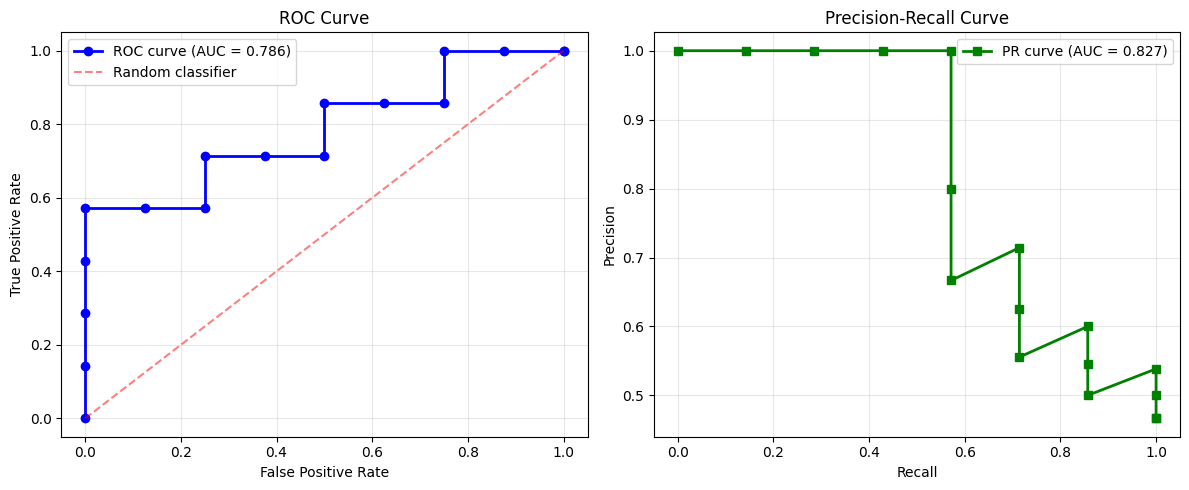

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

P = sum(df['Target'] == 1)
N = sum(df['Target'] == 0)

df_sorted = df.sort_values('Probability_Output', ascending=False)

thresholds = sorted(set(df['Probability_Output']), reverse=True)
thresholds = [1.0] + thresholds + [0.0]

tpr_list, fpr_list, precision_list, recall_list = [], [], [], []

for t in thresholds:
    y_pred = (df['Probability_Output'] >= t).astype(int)

    TP = sum((y_pred == 1) & (df['Target'] == 1))
    FP = sum((y_pred == 1) & (df['Target'] == 0))
    FN = sum((y_pred == 0) & (df['Target'] == 1))

    TPR = TP / P if P > 0 else 0
    FPR = FP / N if N > 0 else 0
    Precision = TP / (TP + FP) if (TP + FP) > 0 else 1.0
    Recall = TPR

    tpr_list.append(TPR)
    fpr_list.append(FPR)
    precision_list.append(Precision)
    recall_list.append(Recall)

print("Порог | TPR    | FPR    | Precision | Recall")
print("-" * 50)
for i, t in enumerate(thresholds):
    print(f"{t:5.2f} | {tpr_list[i]:6.3f} | {fpr_list[i]:6.3f} | {precision_list[i]:9.3f} | {recall_list[i]:6.3f}")

auc_roc = 0
for i in range(1, len(tpr_list)):
    auc_roc += (fpr_list[i] - fpr_list[i-1]) * (tpr_list[i] + tpr_list[i-1]) / 2

auc_pr = 0
for i in range(1, len(recall_list)):
    auc_pr += (recall_list[i] - recall_list[i-1]) * (precision_list[i] + precision_list[i-1]) / 2

print(f"\nAUC-ROC = {auc_roc:.3f}")
print(f"AUC-PR = {auc_pr:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(fpr_list, tpr_list, 'b-', marker='o', linewidth=2, label=f'ROC curve (AUC = {auc_roc:.3f})')
ax1.plot([0, 1], [0, 1], 'r--', alpha=0.5, label='Random classifier')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.set_title('ROC Curve')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(recall_list, precision_list, 'g-', marker='s', linewidth=2, label=f'PR curve (AUC = {auc_pr:.3f})')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.set_title('Precision-Recall Curve')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

PR кривая лучше описывает предсказания модели, так как она лучше работает с несбалансированными моделями и имеет AUC выше.

$$
\text{AUC-ROC} = \frac{1}{\ell_{+} \ell_{-}} \sum_{i: y_i=1} \sum_{j: y_j=0} [a(x_i) > a(x_j)] + \frac{1}{2}I[a(x_i) = a(x_j)]
$$

$$
\text{AUC-PR} = \int_0^1 P(R)  dR
$$

где:
- $\ell_{+}$ - количество положительных примеров
- $\ell_{-}$ - количество отрицательных примеров
- $I$ - индикаторная функция
- $P(R)$ - precision как функция от recall

Мы должны уметь находить всех больных - в этом случае берем порог поменьше, в районе 0,25, нельзя больного классифицировать как здорового. В случае кредитов возьмем порог 0.75, так как нужно точно определить надежных заемщиков и не потерять деньги.

## Задание 2 (1 балл)

1. Покажите, что:
$$
0 \leqslant \text{F1-score} \leqslant 1
$$
2. Покажите, что в случае многоклассовой классификации $Precision_{micro} = Recall_{micro} = Accuracy$

---

1.
$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$$

- Precision и recall лежат в диапазоне $[0, 1]$
- Если precision = 0 или recall = 0, то $F_1 = 0$
- Если precision = 1 и recall = 1, то $F_1 = 1$
- Во всех остальных случаях: $0 < F_1 < 1$

2.
$$\text{Precision}_{micro} = \frac{\sum_{i=1}^C TP_i}{\sum_{i=1}^C TP_i + \sum_{i=1}^C FP_i}$$

$$\text{Recall}_{micro} = \frac{\sum_{i=1}^C TP_i}{\sum_{i=1}^C TP_i + \sum_{i=1}^C FN_i}$$

Но в классификации: $\sum_{i=1}^C FP_i = \sum_{i=1}^C FN_i$

Тогда:
$$\text{Precision}_{micro} = \text{Recall}_{micro} = \frac{\sum_{i=1}^C TP_i}{N} = \text{Accuracy}$$

где $N$ - общее количество примеров, $C$ - количество классов.

## Задание 3* (1 балл)

Построим [U-статистику](https://en.wikipedia.org/wiki/Mann%E2%80%93Whitney_U_test) выборки $X$:

1. Для $X$ получим выходы модели: $O = \{o_i = a(x_i), x_i \in X\}_{i=1}^{\ell}$
2. Упорядочим ответы $o_i$ по неубыванию: $O_+ → (o_{(1)}, \ldots o_{(\ell)})$. В соответствии ответам, получим упорядоченный ряд $(x_{(1)}, \ldots x_{(\ell)}).$
3. Каждому $x_{(i)}$ ставится в соответствии ранг $r_{(i)}$ - номер позиции в ряду (если $o_{(i)}$ совпала с соседями - ранг усредняется по ним).
4. Тогда U-статистика для подвыборки $X$ с положительными метками: $X_+ = \{x_i, x_i \in X, y_i = 1\}_{i=1}^{\ell_+}$:
$$
U_+ = \sum_{i=1, \ y_i=1}^\ell r_{(i)} - \dfrac{\ell_+(\ell_+ + 1)}{2}.
$$

Покажите, что для классификатора $a(x)$ на выборке $X$ верно следующее соотношение
$$
\text{ROC-AUC} = \dfrac{U_+}{\ell_-\ell+}.
$$

---

#### Ваше решение:

---

## 2. PCA

## Задание 4 (3 балла)
В этом задании мы рассмотрим работу PCA как задачу условной оптимизации на симплексе. Полученные результаты пригодятся для практической имплементации.  


### Задача 1 (1.5 балла)

[PCA](https://en.wikipedia.org/wiki/Principal_component_analysis) определяется как преобразование данных, в котором проекции упорядочены по убыванию дисперсии
$$
T = \underbrace{X}_{n\times p}\underbrace{W}_{p\times l}, \quad T = \|t_{(i)}\|_{i=1}^n,\,\,\, t_{(i)} = (t^1_{(i)} \ldots, t^l_{(i)})^\top \in \mathbb{R}^l, \quad x \in \mathbb{R}^p. \tag{1}
$$
Последнее означает, что первая компонента преобразования $w_{(1)}$ удовлетворяет оптимизационной задаче (максимизация дисперсии строки $T$):
$$
w_{(1)} = \arg\max_{w} \left\{\sum_{i}\left[t^1_{(i)}\right]^2\right\} = \arg\max_{w} \left\{\|Xw\|^2\right\}. \tag{2}
$$
Чтобы задача (2) имела конечное решение, оптимизацию проводят на симплексе:
$$
w_{(1)} = \arg\max_{\|w\| = 1} \left\{\|Xw\|^2\right\}. \tag{3}
$$

Покажите, что решением задачи (3) является вектор $u_{(1)}$, соответствующий максимальному собственному значению $\lambda_{(1)}$ матрицы $X^\top X$.

**Указание:** Воспользуйтесь условиями [ККТ](https://en.wikipedia.org/wiki/Karush%E2%80%93Kuhn%E2%80%93Tucker_conditions) для решения задачи условной оптимизации.

---

$$\|X w\|^2 = (X w)^T (X w) = w^T X^T X w$$

$$w^{(1)} = \arg \max_{\|w\|=1} \left\{ w^T X^T X w \right\}$$

Условия ККТ:

$$\mathcal{L}(w, \lambda) = w^T X^T X w - \lambda(w^T w - 1)$$

Условия стационарности:
$$\nabla_w \mathcal{L} = 2X^T X w - 2\lambda w = 0$$
$$X^T X w = \lambda w$$

Это означает, что $w$ — собственный вектор матрицы $X^T X$, а $\lambda$ — соответствующее собственное значение.

Целевая функция в стационарной точке:
$$w^T X^T X w = w^T (\lambda w) = \lambda \|w\|^2 = \lambda$$

Для максимизации нужно выбрать максимальное собственное значение $\lambda_{\max}$.

### Задача 2 (0.5 балла)

Вторая компонента $t_{(2)} = w_{(2)}^\top X$ должна иметь следующую по величине дисперсию.

Однако в таком предположении мы всегда можем выбрать $t_{(2)} = (1 - \varepsilon_{(1)})t_{(1)}$ для сколь угодно малого $\varepsilon_{(1)} > 0$. Аналогично $t_{(3)} = (1 - \varepsilon_{(2)})t_{(2)}$ и так далее. Таким образом, разложение $X$ теряет смысл, поскольку вектора $t_{(1)}, \ldots, t_{(n)}$ являются коллинеарными.

Чтобы получить осмысленное разложение, потребуем чтобы $t_{(2)}$ *некоррелировал* с $t_{(1)}$.

Покажите, что для этого необходимо, чтобы $w_{(2)}^\top u_{(1)} = 0$.

---

Условие некоррелированности
$$\text{cov}(t_{(1)}, t_{(2)}) = 0$$

Выразим ковариацию через веса
$$\text{cov}(t_{(1)}, t_{(2)}) = \mathbb{E}[(t_{(1)} - \mathbb{E}[t_{(1)}])(t_{(2)} - \mathbb{E}[t_{(2)}])]$$

При центрированных данных ($\mathbb{E}[X] = 0$):
$$\text{cov}(t_{(1)}, t_{(2)}) = \mathbb{E}[t_{(1)}t_{(2)}] = \mathbb{E}[(w_{(1)}^{\top}X)(w_{(2)}^{\top}X)]$$

$$\mathbb{E}[(w_{(1)}^{\top}X)(w_{(2)}^{\top}X)] = w_{(1)}^{\top} \mathbb{E}[XX^{\top}] w_{(2)} = w_{(1)}^{\top} \Sigma w_{(2)}$$

где $\Sigma = \mathbb{E}[XX^{\top}]$ - ковариационная матрица данных.

Для ковариационной матрицы $\Sigma$ выполняется:
$$\Sigma u_{(1)} = \lambda_{(1)} u_{(1)}$$

Условие ортогональности
$$\text{cov}(t_{(1)}, t_{(2)}) = u_{(1)}^{\top} \Sigma w_{(2)} = u_{(1)}^{\top} (\lambda_{(1)} u_{(1)}) w_{(2)} = \lambda_{(1)} (u_{(1)}^{\top} u_{(1)}) (u_{(1)}^{\top} w_{(2)})$$

Так как $u_{(1)}^{\top} u_{(1)} = 1$, то:
$$\text{cov}(t_{(1)}, t_{(2)}) = \lambda_{(1)} (u_{(1)}^{\top} w_{(2)})$$

Для выполнения $\text{cov}(t_{(1)}, t_{(2)}) = 0$ необходимо:
$$\lambda_{(1)} (u_{(1)}^{\top} w_{(2)}) = 0$$

Поскольку $\lambda_{(1)} > 0$ (максимальное собственное значение), получаем:
$$u_{(1)}^{\top} w_{(2)} = 0$$

### Задача 3 (0.5 балла)

Задача оптимизации для $w_{(2)}$ с учётом 4.2
$$
w_{(2)} = \arg\max_{\|w\| = 1, \\ w \in H_1} \left\{\|Xw\|^2\right\}, \quad H_1 = \{w : w^\top u_{(1)} = 0\}.
$$
В общем случае для $w_{(j)}$
$$
w_{(j)} = \arg\max_{\|w\| = 1, \\ w \in H_{j-1}} \left\{\|Xw\|^2\right\}, \quad H_{j-1} = \left\{w : w^\top u_{(k)} = 0, \,\, k=\overline{1, j-1}\right\}. \tag{4}
$$

Покажите, что решением задачи (4) является вектор $u_{(j)}$, соответствующий $j$-му собственному значению $\lambda_{(j)}$ матрицы $X^\top X$.

**Указание:** Воспользуйтесь условиями [ККТ](https://en.wikipedia.org/wiki/Karush%E2%80%93Kuhn%E2%80%93Tucker_conditions) для решения задачи условной оптимизации.

---


Условия ККТ
Функция Лагранжа с ограничениями:
$$\mathcal{L}(w, \lambda, \mu_1, \ldots, \mu_{j-1}) = w^\top X^\top X w - \lambda(w^\top w - 1) - \sum_{k=1}^{j-1} \mu_k w^\top u_{(k)}$$

Условия стационарности
$$\nabla_w \mathcal{L} = 2X^\top X w - 2\lambda w - \sum_{k=1}^{j-1} \mu_k u_{(k)} = 0$$

Умножим уравнение на $u_{(m)}$ для $m = 1, \ldots, j-1$:
$$2u_{(m)}^\top X^\top X w - 2\lambda u_{(m)}^\top w - \sum_{k=1}^{j-1} \mu_k u_{(m)}^\top u_{(k)} = 0$$

Учитывая, что:
- $u_{(m)}^\top X^\top X = \lambda_{(m)} u_{(m)}^\top$ (т.к. $X^\top X u_{(m)} = \lambda_{(m)} u_{(m)}$)
- $u_{(m)}^\top w = 0$ (ограничения)
- $u_{(m)}^\top u_{(k)} = \delta_{mk}$ (ортонормированность)

Получаем:
$$2\lambda_{(m)} u_{(m)}^\top w - \mu_m = 0 \Rightarrow \mu_m = 0$$

Поскольку все $\mu_k = 0$, уравнение стационарности упрощается:
$$2X^\top X w - 2\lambda w = 0 \Rightarrow X^\top X w = \lambda w$$

Из ограничений $w^\top u_{(k)} = 0$ для $k = 1, \ldots, j-1$ следует, что $w$ должен быть ортогонален первым $j-1$ собственным векторам.

Поскольку собственные векторы ортонормированы, остаётся выбрать $w = u_{(j)}$ — следующий по величине собственного значения вектор.

### Задача 4 (0.5 балла)

Из предыдущих 3-х пунктов мы выяснили, что процедура построения главных компонент сводится к поиску собственных векторов матрицы $X^\top X$.

На практике бывает полезно центрировать матрицу $X \rightarrow \bar{X}$. Действительно, с точки зрения разложения, выражения $X^\top X$ и $\bar{X}^\top \bar{X}$ связаны соотношением:
$$
X^\top X = \bar{X}^\top \bar{X} + n\mu\mu^\top,
$$
где $\mu = \frac{1}{n}\sum_i x_i$ - выборочное среднее $X$. Тогда, если данные сильно смещены, с.в. и с.з. $X^\top X$ определяются слагаемым смещения и не содержат реальной информации о главных компонентах разложения.

---

В центрированном случае $X = \bar{X}$ и $\bar{X}^\top \bar{X}$ имеет смысл *матрицы ковариации* $cov(X, X) = \frac{1}{n-1}\bar{X}^\top \bar{X}$.

---

Рассмотрим Kernel-PCA, использующий ядерный трюк:
$$
\mathcal{K}: \mathcal{X}\times\mathcal{X} \rightarrow \mathbb{R}, \quad \mathcal{K}(x_i, x_j) = \langle \psi(x_i), \psi(x_j) \rangle,\,\,\, \psi(x) \in \mathbb{R}^P, P > p.
$$

Тогда соответствующая матрица ковариации представлена *матрицей Грама*: $cov(X, X) → K(X, X) = \|\mathcal{K}(x_i, x_j)\|_{i, j}^n$.


Аналогично PCA, давайте центрируем матрицу Грама. Определим $\bar{\psi}(x_i) = \psi(x_i) - \mu$, где $\mu = \frac{1}{n}\sum_{i=1}^n \psi(x_i)$ и $\bar{K}(X, X) = \|\mathcal{K}(x_i, x_j)\|_{i, j}^n$.

Покажите, что
$$
\bar{K} = K - \mathbf{1_n} \cdot K - K \cdot \mathbf{1_n} + \mathbf{1_n} \cdot K \cdot \mathbf{1_n}, \quad K = \|\mathcal{K}(x_i, x_j)\|_{i, j}^n,\,\,\, \mathbf{1_n} \equiv \|1 / n\|_{i, j}^n.
$$

Эта формула нам пригодится при ручной имплементации Kernel-PCA.

---

$$\bar{\mathcal{K}}(x_i, x_j) = \langle \psi(x_i) - \mu, \psi(x_j) - \mu \rangle$$

$$\bar{\mathcal{K}}(x_i, x_j) = \langle \psi(x_i), \psi(x_j) \rangle - \langle \psi(x_i), \mu \rangle - \langle \mu, \psi(x_j) \rangle + \langle \mu, \mu \rangle$$

Используем $\mathcal{K}(x_i, x_j) = \langle \psi(x_i), \psi(x_j) \rangle$:

$$\bar{\mathcal{K}}(x_i, x_j) = \mathcal{K}(x_i, x_j) - \langle \psi(x_i), \mu \rangle - \langle \mu, \psi(x_j) \rangle + \langle \mu, \mu \rangle$$

Выразим средние значения через ядро
$$\langle \psi(x_i), \mu \rangle = \frac{1}{n} \sum_{k=1}^n \langle \psi(x_i), \psi(x_k) \rangle = \frac{1}{n} \sum_{k=1}^n \mathcal{K}(x_i, x_k)$$

$$\langle \mu, \psi(x_j) \rangle = \frac{1}{n} \sum_{k=1}^n \langle \psi(x_k), \psi(x_j) \rangle = \frac{1}{n} \sum_{k=1}^n \mathcal{K}(x_k, x_j)$$

$$\langle \mu, \mu \rangle = \frac{1}{n^2} \sum_{k=1}^n \sum_{l=1}^n \langle \psi(x_k), \psi(x_l) \rangle = \frac{1}{n^2} \sum_{k=1}^n \sum_{l=1}^n \mathcal{K}(x_k, x_l)$$

В матричной форме для всех $i,j$:

$$\bar{\mathcal{K}} = \mathcal{K} - \frac{1}{n} \mathbf{1}_n \mathcal{K} - \frac{1}{n} \mathcal{K} \mathbf{1}_n + \frac{1}{n^2} \mathbf{1}_n \mathcal{K} \mathbf{1}_n$$

где:
- $\mathcal{K} = \| \mathcal{K}(x_i, x_j) \|_{i,j}^n$ - исходная ядерная матрица
- $\mathbf{1}_n = \| 1 \|_{i,j}^n$ - матрица из единиц размера $n \times n$

Если определить $\mathbf{1}_n \equiv \| \mathbf{1}/n \|_{i,j}^n$, то формула принимает вид:

$$\bar{\mathcal{K}} = \mathcal{K} - \mathbf{1}_n \cdot \mathcal{K} - \mathcal{K} \cdot \mathbf{1}_n + \mathbf{1}_n \cdot \mathcal{K} \cdot \mathbf{1}_n$$

## Задание 5 (1 балл)

Покажите, что описанная процедура PCA инвариантна относительно поворота:

1. Согласно заданию 4.1-4.3 определим PCA как
$$
T = \underbrace{X}_{n\times p}\underbrace{W}_{p\times l}, \quad T = \|t_{(i)}\|_{i=1}^n,\,\,\, t_{(i)} = (t^1_{(i)} \ldots, t^l_{(i)})^\top \in \mathbb{R}^l, \quad x \in \mathbb{R}^p.
$$
2. Определим матрицу поворота $Q$ и "повёрнутые" данные $\tilde{X}$:
$$
\tilde{X} = XQ.
$$
3. Определим PCA-преобразование над $\tilde{X}$
$$
\widetilde{T} = \tilde{X}\tilde{W}.
$$
4. Тогда инвариантность означает $T = \widetilde{T}$


**Подсказка:** Воспользуйтесь тем, что $W$ и $\tilde{W}$ определяются собственными векторами соответствующих матриц ковариации $X^\top X$ и $\tilde{X}^\top\tilde{X}$, а также что матрица поворота $Q$ обладает свойством ортогональности.

---

Найдём матрицу ковариации для повёрнутых данных
$$\tilde{X}^T\tilde{X} = (XQ)^T(XQ) = Q^TX^TXQ$$

Пусть $W$ - собственные векторы $X^TX$: $X^TXW = W\Lambda$

Тогда для $\tilde{X}^T\tilde{X}$:
$$\tilde{X}^T\tilde{X}(QW) = Q^TX^TXQ(QW) = Q^TX^TXW = Q^TW\Lambda = (QW)\Lambda$$

Это означает, что $QW$ - собственные векторы $\tilde{X}^T\tilde{X}$

По определению PCA, $\tilde{W}$ состоит из собственных векторов $\tilde{X}^T\tilde{X}$, поэтому:
$$\tilde{W} = QW$$

Для повёрнутых данных
$$\tilde{T} = \tilde{X}\tilde{W} = (XQ)(QW) = X(QQ^T)W$$

Так как $Q$ ортогональна ($QQ^T = I$), получаем:
$$\tilde{T} = XIW = XW = T$$

## Задание 6* (1 балл)

Процедура построения главных компонент требует их некоррелированности: $cov(t_{(i)}, t_{(j)}) = 0$, $\forall\, i, j$.

Вместе с этим, некоррелированность не гаранирует статитстическую независимость.

1. Приведите пример PCA разложения, в котором $t_{(i)}, t_{(j)}$ являются зависимыми случайными величинами.

2. Покажите что в случае $\underbrace{X}_{n\times p} \sim \mathcal{N}(\mu, \Sigma)$ при $n \to \infty$ главные компоненты будут независимыми случайными величинами. Почему важно условие $n \to \infty$? Ответ обоснуйте или приведите пример.

---

#### Ваше решение:

---

## Задание 7* (1 балл)

#### Связь вероятностного и классического PCA

1. Определим *вероятностный PCA* как *модель скрытой переменной*:
$$
x = zW^\top + \varepsilon. \tag{5}
$$
2. Полученные с помощью решения (4) главные компоненты $t_{(1)}, \ldots, t_{(p)}$ можно использовать для уменьшения размерности X:
$$
T_l = XW_l, \quad T_l = \|t_{(i)}\|_{i=1}^l.
$$
В силу процедуры построения $W_l$ ортонормированна: $W_lW_l^\top = I_l$, тогда
$$
T_lW_l^\top = X I_l \overset{\mathrm{def}}{=} X_l. \tag{6}
$$
В результате чего $X_l$ является сжатым представлением $X$.
3. Качество компрессии можно оценивать с помощью $X - X_l = \varepsilon$:
$$
X = X_l + \varepsilon = T_lW_l^\top + \varepsilon.
$$
4. Проводя оценку для конкретного примера $x_i$ и $z_i = t_{(i)}$ мы получаем соответствие моделей (5) и (6).

Однако, для того чтобы утверждать, что модель скрытой переменной (5) является вероятностной версией PCA, необходимо показать, что процедура оптимизации такой модели совпадает с процедурой оптимизации (6).



*   Покажите связь PCA с SVD разложением:
$$
X = U\Sigma V^\top, \quad W^\top = \Sigma V^\top.
$$
*  Покажите, что оптимизация (5) по $W$ даст $W^\top = \Sigma V^\top$ в априорных предположениях $\varepsilon \sim \mathcal{N}(0, \sigma I^2)$ и $p(z) = \mathcal{N}(0, I)$ при $\sigma \to 0$. Для этого воспользуйтесь максимизацией логарифма правдоподобия $\log p(x | W, \sigma)$.

---

#### Ваше решение:

---

# Практическая часть

In [5]:
from typing import Callable
import os
import pandas as pd
import numpy as np
import gdown
from PIL import Image
import matplotlib.pyplot as plt

In [6]:
def download_with_shared_id(file_id, filename):
    url = f"https://drive.google.com/uc?export=download&id={file_id}"
    gdown.download(url, filename, quiet=False)

## Задание 8 (8.5 баллов)
#### PCA on sythetic data

В папке с заданием вы найдёте файл `synthetic_data.csv`. Вы можете напрямую загрузить файл во временной окружение или воспользоваться кодом ниже

In [7]:
synthetic_data_file_id = '1mB6bUInPMxUmvLf58SA33Jd1ZQOe1OWc'
download_with_shared_id(synthetic_data_file_id, 'synthetic_data.csv')
df = pd.read_csv('synthetic_data.csv')
df.head(5)

Downloading...
From: https://drive.google.com/uc?export=download&id=1mB6bUInPMxUmvLf58SA33Jd1ZQOe1OWc
To: /content/synthetic_data.csv
100%|██████████| 253k/253k [00:00<00:00, 5.61MB/s]


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,label
0,0.373742,2.082607,1.384016,0.232210,1.867932,0.799906,1.569763,1.743720,2.718933,3.638285,0.581565,1.133964,-0.613302,0
1,-1.651953,2.433542,0.968096,0.000237,1.823808,0.298767,0.968167,0.975870,2.448763,1.862862,0.113761,1.138231,-1.089608,0
2,-0.940813,3.277671,1.587022,0.000137,1.999868,0.421152,1.587080,1.371682,3.291364,3.861090,-0.097646,1.689374,-0.887808,0
3,-0.532969,2.683229,2.297609,0.005673,1.747180,0.594575,2.300983,1.788795,2.783969,3.345638,0.186806,1.312156,-0.544618,0
4,-1.067956,2.409374,0.915896,0.002368,1.793093,0.441066,0.916941,1.091797,2.460215,1.920850,0.151944,1.277589,-0.769468,0


### Задача 1 (0.5 балла)
#### Анализ данных

1. Проведите базовый исследовательский анализ предложенных данных.
    *   Исследуйте распределение меток
    *   Визуализируйте зависимости между компонентами примеров

    (Анализ данных не обязан ограничиваться данными пунктами)
2. Выберите метрики для дальнейшего тестирования
3. Для того, чтобы тестирование вашей имплементации PCA было корректным, **важно** не изменять структуру и содержимое `df`.

Размерность: (998, 14)

2. Анализ распределения меток:
Метка: label
Уникальные значения: [0 1 2 3 4 5]
Распределение:
label
0    498
1    200
2    100
3     80
4     70
5     50
Name: count, dtype: int64


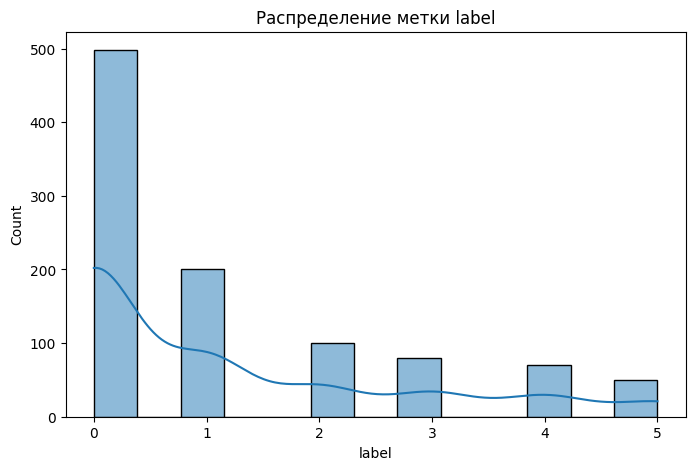

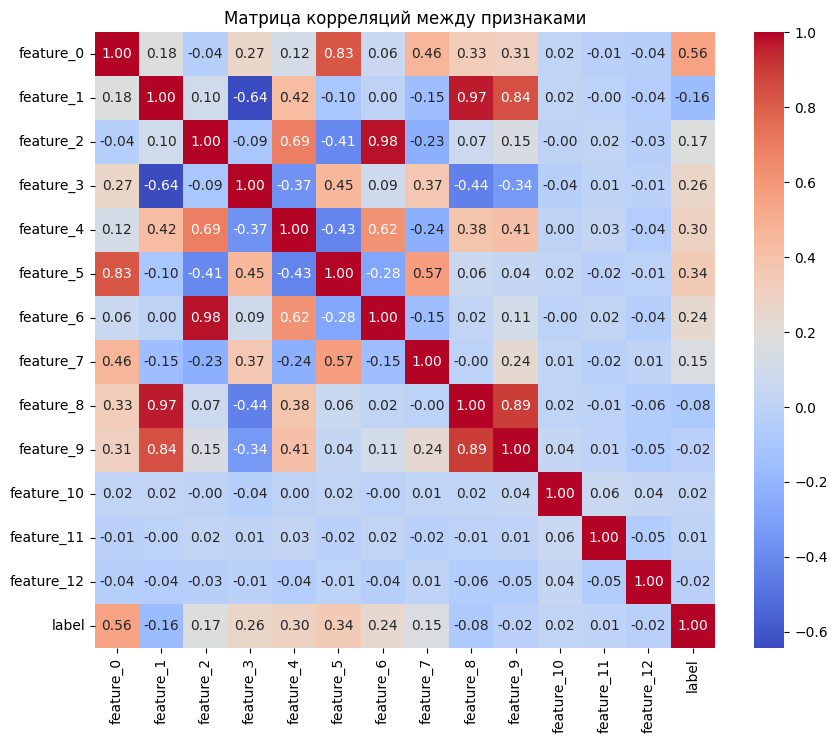

Попарные зависимости (первые 4 признака):


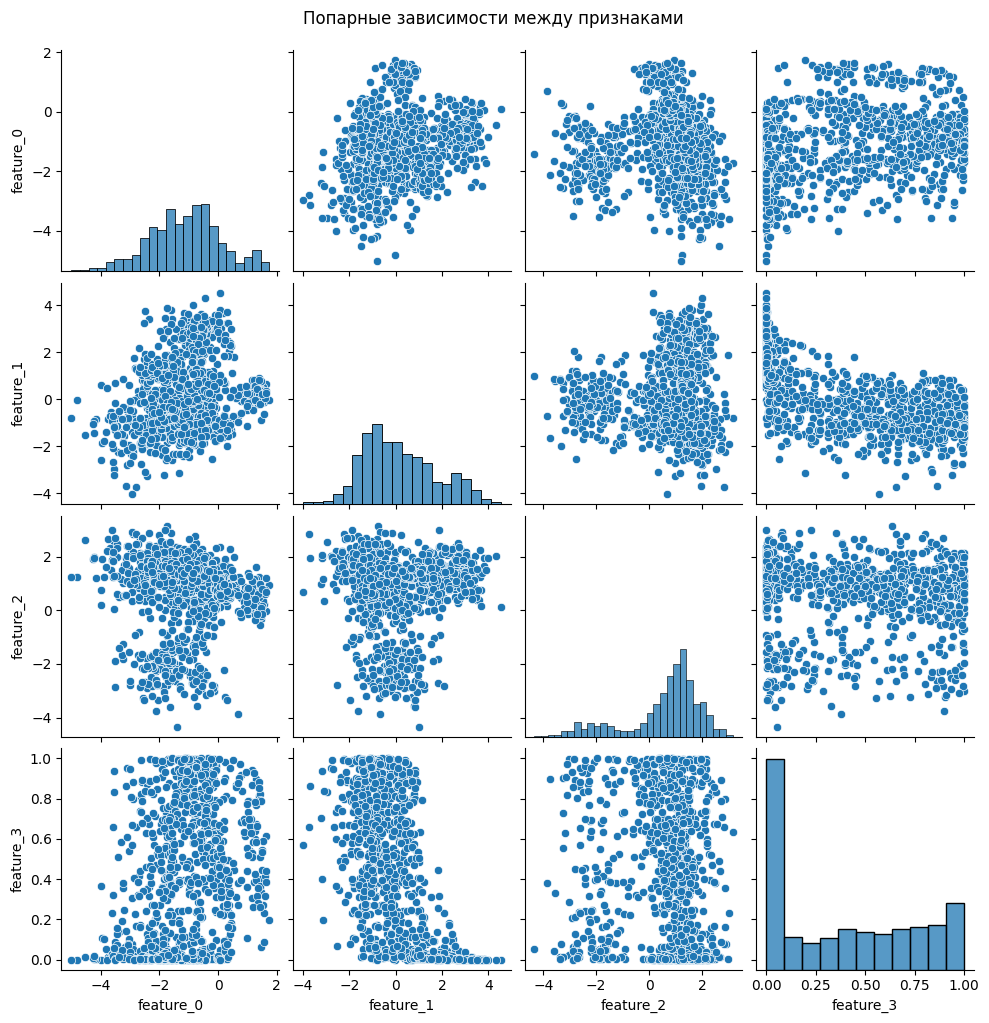

In [8]:
import seaborn as sns

print(f"Размерность: {df.shape}")

print("\n2. Анализ распределения меток:")
target_column = df.columns[-1]
print(f"Метка: {target_column}")
print(f"Уникальные значения: {df[target_column].unique()}")
print(f"Распределение:\n{df[target_column].value_counts()}")

plt.figure(figsize=(8, 5))
sns.histplot(df[target_column], kde=True)
plt.title(f'Распределение метки {target_column}')
plt.show()

# Матрица корреляций
plt.figure(figsize=(10, 8))
corr_matrix = df.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Матрица корреляций между признаками')
plt.show()

print("Попарные зависимости (первые 4 признака):")
sns.pairplot(df[df.columns[:4]])
plt.suptitle('Попарные зависимости между признаками', y=1.02)
plt.show()

Выберем метрики:
1. Объяснённая дисперсия компонент - Определить информативность отдельных компонент
- Что измеряет: Долю общей дисперсии, объясняемую каждой компонентой
- Формула: $\frac{\lambda_i}{\sum_{j=1}^p \lambda_j}$, где $\lambda_i$ - собственные значения

2. Суммарная объяснённая дисперсия - Найти минимальное $k$, сохраняющее требуемую долю информации
- Что измеряет: Накопленную долю дисперсии от первых $k$ компонент  
- Формула: $\frac{\sum_{i=1}^k \lambda_i}{\sum_{j=1}^p \lambda_j}$

3. Реконструкционная ошибка - Оценить потери информации при сжатии
- Что измеряет: Качество восстановления данных после снижения размерности
- Формула: $\|X - X_{\text{reconstructed}}\|_F^2$

В случае данных, природа которых нам не ясна, имеет смысл проводить *стандартизацию.* Стандартизация проводится на основе статистик датасета (среднее, дисперсия). Хорошим тоном является подсчёт таких статистик только для тренировочной части выборки. В этом случае мы исключаем неявное "подсматривание" в тестовый набор, получая более объективные результаты предсказаний.

Делать мы так, конечно же, не будем 😃🤗😃 (чтобы не усложнять себе жизнь при понижении размерности с помощью PCA).

In [9]:
from sklearn.model_selection import train_test_split

# Separate features and labels
X = df.drop(columns='label')
y = df['label']

Проведите стандартизацию (для этого воспользуйтесь модулем `sklearn.preprocessing.StandardScaler`)

In [10]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns='label')
y = df['label']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

print("\nСтандартизированные данные - первые 5 строк:")
print(X_scaled.head())


Стандартизированные данные - первые 5 строк:
   feature_0  feature_1  feature_2  feature_3  feature_4  feature_5  \
0   1.228414   1.235357   0.569582  -0.475580   0.816635   0.866585   
1  -0.458434   1.461170   0.272890  -1.129980   0.752274  -0.978972   
2   0.133751   2.004335   0.714394  -1.130264   1.009082  -0.528261   
3   0.473373   1.621834   1.221283  -1.114645   0.640501   0.110408   
4   0.027876   1.445619   0.235654  -1.123971   0.707471  -0.454923   

   feature_6  feature_7  feature_8  feature_9  feature_10  feature_11  \
0   0.525960   0.957294   1.482334   1.849223    2.358154    0.097234   
1   0.083227  -1.336599   1.272850   0.629382    0.716686    0.110425   
2   0.538705  -0.154140   1.926185   2.002306   -0.025117    1.813886   
3   1.064088   1.091953   1.532762   1.648154    0.972993    0.647987   
4   0.045528  -0.990275   1.281730   0.669224    0.850665    0.541149   

   feature_12  
0    0.683833  
1   -0.582906  
2   -0.046219  
3    0.866499  
4    0.2

### Задача 2 (1 балл)
#### Имплементация PCA

Самостоятельно имплементируйте метод главных компонент согласно утверждению из Задания 4.3.

1.   Постройте матрицу $X^\top X$. Вы можете воспользоваться тем что
$$
cov(X, X) = \dfrac{1}{n-1}\overline{X}^\top\overline{X}, \quad \overline{X} = X - mean(X).
$$
2. Найдите собственные значения и собственные векторы матрицы $X^\top X$
3. Отсортируйте с.з. и с.в. в убывающем порядке.

**Примечание:** Для выполнения пунктов 1-2 вы можете пользоваться соответствующим функционалом библиотеки `numpy`.

In [11]:
def get_pca_components(cov_matrix):

    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    sorted_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sorted_indices]
    eigenvectors = eigenvectors[:, sorted_indices]

    return eigenvalues, eigenvectors

cov_matrix = np.cov(X_scaled, rowvar=False, bias=False)

eigenvalues, eigenvectors = get_pca_components(cov_matrix)

In [12]:
def assert_eigenvalues(eigenvalues: np.ndarray) -> None:
    true_eigenvalues = np.array([3.71065006e+00, 2.83985667e+00, 2.00690398e+00, 1.06056661e+00,
                                 1.04028115e+00, 8.96689475e-01, 6.42816087e-01, 4.42744367e-01,
                                 2.94271935e-01, 5.91739353e-02, 1.65303064e-02, 1.55655953e-03,
                                 9.97985951e-04]
                              )
    assert np.allclose(true_eigenvalues, eigenvalues, atol=1e-6), "Eigenvalues are not equivalent"
    print("Success!!!")

assert_eigenvalues(eigenvalues)

Success!!!


Построим график суммарной объясняемой дисперсии (Cumulative Explained Variance) от количества главных компонент.

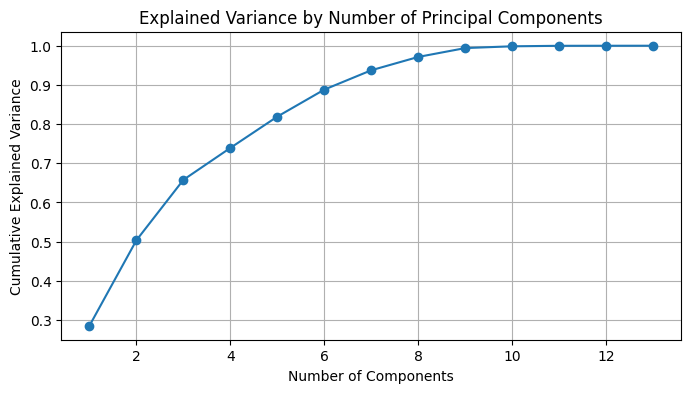

In [13]:
# Calculate explained variance for each component
explained_variance_ratio = eigenvalues / eigenvalues.sum()

# Plot explained variance
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(explained_variance_ratio) + 1), np.cumsum(explained_variance_ratio), marker='o')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance by Number of Principal Components')
plt.grid(True)
plt.show()

Одной из особенностей предложенного набора данных является дисбаланс классов (мы надеемся, что вы это выяснили в ходе анализа данных). Таким образом, корректное разделение выборки на обучение и тест должно быть [стратифицированным](https://scikit-learn.org/stable/modules/cross_validation.html#stratification).

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Задача 3 (2 балла)
#### Классификация

Проведите обучение и тестирование логистической регрессии. Данные должны проецироваться на полученные главные компоненты (см. (1) в задании 4.1). Постройте графики зависимости выбранных метрик от количества главных компонент. Сделайте выводы.

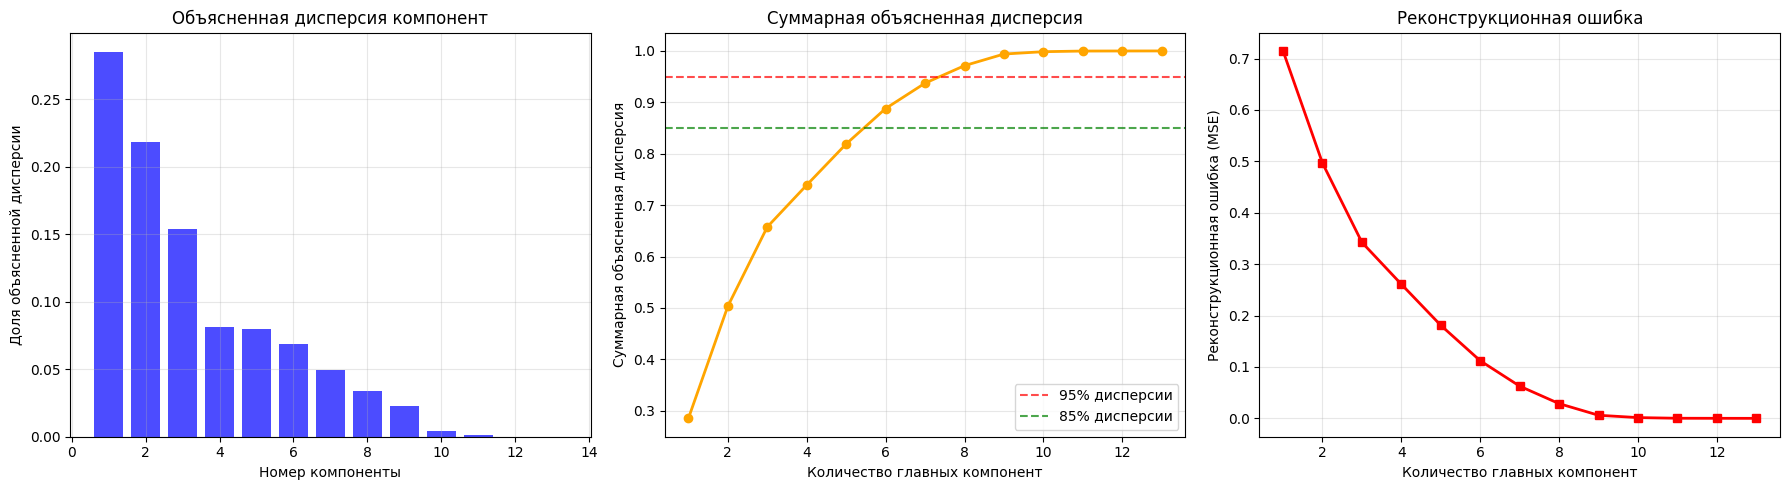

Компонент для 85% дисперсии: 6
Компонент для 95% дисперсии: 8
Реконструкционная ошибка при 6 компонентах: 0.1120
Реконструкционная ошибка при 8 компонентах: 0.0286


In [15]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np


def evaluate_pca_metrics(n_components, X_data):
    pca = PCA(n_components=n_components, random_state=42)
    X_pca = pca.fit_transform(X_data)

    explained_variance = pca.explained_variance_ratio_
    cumulative_variance = np.cumsum(explained_variance)

    X_reconstructed = pca.inverse_transform(X_pca)
    reconstruction_error = np.mean((X_data - X_reconstructed) ** 2)

    metrics = {
        'explained_variance': explained_variance,
        'cumulative_variance': cumulative_variance[-1] if len(cumulative_variance) > 0 else 0,
        'reconstruction_error': reconstruction_error,
        'n_components': n_components
    }

    return metrics

max_components = X_scaled.shape[1]
components_range = range(1, max_components + 1)

results = []
individual_variances = []

for n_comp in components_range:
    metrics = evaluate_pca_metrics(n_comp, X_scaled)
    results.append(metrics)

    if n_comp == 1:
        individual_variances = metrics['explained_variance'].tolist()
    else:
        individual_variances.extend(metrics['explained_variance'][-1:])

results_df = pd.DataFrame(results)

# Построение графиков выбранных метрик
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].bar(range(1, len(individual_variances) + 1), individual_variances, alpha=0.7, color='blue')
axes[0].set_xlabel('Номер компоненты')
axes[0].set_ylabel('Доля объясненной дисперсии')
axes[0].set_title('Объясненная дисперсия компонент')
axes[0].grid(True, alpha=0.3)

axes[1].plot(results_df['n_components'], results_df['cumulative_variance'],
             marker='o', linewidth=2, color='orange')
axes[1].axhline(y=0.95, color='r', linestyle='--', alpha=0.7, label='95% дисперсии')
axes[1].axhline(y=0.85, color='g', linestyle='--', alpha=0.7, label='85% дисперсии')
axes[1].set_xlabel('Количество главных компонент')
axes[1].set_ylabel('Суммарная объясненная дисперсия')
axes[1].set_title('Суммарная объясненная дисперсия')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

axes[2].plot(results_df['n_components'], results_df['reconstruction_error'],
             marker='s', linewidth=2, color='red')
axes[2].set_xlabel('Количество главных компонент')
axes[2].set_ylabel('Реконструкционная ошибка (MSE)')
axes[2].set_title('Реконструкционная ошибка')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Находим оптимальное количество компонент для 85% и 95% дисперсии
components_95 = np.argmax(results_df['cumulative_variance'] >= 0.95) + 1
components_85 = np.argmax(results_df['cumulative_variance'] >= 0.85) + 1

print(f"Компонент для 85% дисперсии: {components_85}")
print(f"Компонент для 95% дисперсии: {components_95}")

# Анализ реконструкционной ошибки
print(f"Реконструкционная ошибка при {components_85} компонентах: {results_df.iloc[components_85-1]['reconstruction_error']:.4f}")
print(f"Реконструкционная ошибка при {components_95} компонентах: {results_df.iloc[components_95-1]['reconstruction_error']:.4f}")

Из объясненной дисперсии - первые компоненты несут основную информацию, из суммарной дисперсия - для 85-95% информации достаточно 6-8 компонент

### Задача 4 (5 баллов)
#### Имплементация Kernel-PCA

Приступим к имплементации Kernel-PCA😋.

Цель та же - найти с.з. и с.в. Однако вместо поиска их у матрицы ковариации $cov(X, X)$ будем искать их для матрицы Грама (см. задание 4.4).

Будем рассматривать следующие типы ядерных функций:

* Линейное $K_{L}(X,Y) =  X Y^\top$
* Полиномиальное $K_{d, c}(X,Y) = (X Y^\top + c)^d$
* Радиально-Базисная Функция (РБФ) $K_\gamma(X, Y) = \exp\left\{\gamma\|X-Y\|^2\right\}$
* Сигмоидальная $\sigma_{\gamma}(X, Y) = \tanh{(\gamma\cdot X Y^\top + c)}$
* Косинусная $cos(X, Y) = X Y^\top / (\|X\|*\|Y\|)$

#### Задача 4.1 (1 балл)
Необходимо имплементировать перечисленные ядерные функции

In [16]:
def linear_kernel(X, Y=None):
    if Y is None:
        Y = X
    kernel = X @ Y.T
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def poly_kernel(X, Y=None, degree=3, coef=1.):
    if Y is None:
        Y = X
    kernel = (X @ Y.T + coef) ** degree
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def rbf_kernel(X, Y=None, gamma=None):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]
    X_norm = np.sum(X**2, axis=1).reshape(-1, 1)
    Y_norm = np.sum(Y**2, axis=1).reshape(1, -1)
    squared_distances = X_norm + Y_norm - 2 * (X @ Y.T)
    kernel = np.exp(-gamma * squared_distances)
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def sigmoid_kernel(X, Y=None, gamma=None, coef=1.):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]
    kernel = np.tanh(gamma * (X @ Y.T) + coef)
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

def cosine_kernel(X, Y=None, gamma=None, coef=1.):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]
    X_norm = np.linalg.norm(X, axis=1).reshape(-1, 1)
    Y_norm = np.linalg.norm(Y, axis=1).reshape(1, -1)
    kernel = (X @ Y.T) / (X_norm @ Y_norm)
    assert kernel.shape == (X.shape[0], Y.shape[0])
    return kernel

Полученную матрицу необходимо центрировать. Воспользуемся результатом задания 4.4:
$$
\bar{K} = K - \mathbf{1_n} \cdot K - K \cdot \mathbf{1_n} + \mathbf{1_n} \cdot K \cdot \mathbf{1_n}, \quad K = \|\mathcal{K}(x_i, x_j)\|_{i, j}^n,\,\,\, \mathbf{1_n} \equiv \|1 / n\|_{i, j}^n.
$$

#### Задача 4.2 (0.5 балла)
Имплементируйте центрирование матрицы Грама

In [17]:
def center_kernel(K):
    n = K.shape[0]
    ones_n = np.ones((n, n)) / n
    K_centered = K - ones_n @ K - K @ ones_n + ones_n @ K @ ones_n
    return K_centered

Соберём все в класс `KernelPCA`

In [18]:
class KernelPCA:
    def __init__(self, n_components: int, kernel: Callable, **kernel_params) -> None:
        self.n_components = n_components
        assert isinstance(kernel, Callable), f"kernel should be Callable, you provide {type(kernel)}"
        self.kernel = kernel
        self.kernel_params = kernel_params
        self.eigenvalues = None
        self.eigenvectors = None

    def fit_transform(self, X):
        K = self.kernel(X, **self.kernel_params)
        K_centered = center_kernel(K)
        self.eigenvalues, self.eigenvectors = get_pca_components(K_centered)
        self.eigenvalues = np.clip(self.eigenvalues, a_min=0, a_max=None)
        # Normalize eigenvectors (each column divided by sqrt(eigenvalue))
        self.eigenvectors = self.eigenvectors / np.sqrt(self.eigenvalues + 1e-10)
        self.eigenvalues = self.eigenvalues[:self.n_components]
        return np.dot(K_centered, self.eigenvectors[:, :self.n_components])

Проверка имплементации

In [19]:
def assert_kpca():
    n_components = 13

    linear_answers = np.array([
        1.00000000e+00, 7.65325918e-01, 5.40849701e-01, 2.85816930e-01,
        2.80350109e-01, 2.41652934e-01, 1.73235437e-01, 1.19317198e-01,
        7.93046851e-02, 1.59470536e-02, 4.45482761e-03, 4.19484323e-04,
        2.68951783e-04
    ])

    poly_answers = np.array([
        1.00000000e+00, 8.38128700e-01, 5.16131520e-01, 3.77038000e-01,
        3.08713630e-01, 2.78047060e-01, 2.57149900e-01, 2.43782890e-01,
        2.24221330e-01, 2.07156400e-01, 1.82629920e-01, 1.66992480e-01,
        1.57221440e-01
    ])

    rbf_answers = np.array([
        1.00000000e+00, 7.15032620e-01, 6.79436430e-01, 3.15607890e-01,
        3.05523880e-01, 2.87117720e-01, 2.84299700e-01, 2.72074470e-01,
        2.42323240e-01, 1.87167890e-01, 1.48309100e-01, 1.37459850e-01,
        1.28174180e-01
    ])

    sigmoid_answers = np.array([
        1.00000000e+00, 7.61327120e-01, 4.70978290e-01, 3.01313000e-01,
        2.95793220e-01, 2.54351330e-01, 1.15666760e-01, 9.23709900e-02,
        4.52054200e-02, 1.68690600e-02, 1.42803400e-02, 1.14450900e-02,
        1.03591100e-02
    ])

    cosine_answers = np.array([
        1.00000000e+00, 7.13192056e-01, 5.48668783e-01, 2.99406183e-01,
        2.88770492e-01, 2.72318496e-01, 1.81658909e-01, 1.31574265e-01,
        7.24384288e-02, 1.31406641e-02, 4.31671372e-03, 4.67396214e-04,
        2.88007519e-04
    ])

    true_eigenvalues = {
        'linear': linear_answers,
        'poly': poly_answers,
        'rbf': rbf_answers,
        'sigmoid': sigmoid_answers,
        'cosine': cosine_answers
    }

    kernels = [linear_kernel, poly_kernel, rbf_kernel, sigmoid_kernel, cosine_kernel]

    for kernel in kernels:
        kpca = KernelPCA(n_components=n_components, kernel=kernel)

        if hasattr(X_scaled, 'values'):
            X_array = X_scaled.values
        else:
            X_array = X_scaled

        if X_array.ndim == 1:
            X_array = X_array.reshape(-1, 1)

        _ = kpca.fit_transform(X_array)
        target_eigenvalues = kpca.eigenvalues / kpca.eigenvalues[0]
        kernel_name = kernel.__name__.replace('_kernel', '')

        print(f"\n{kernel_name}:")
        print(f"True: {true_eigenvalues[kernel_name]}")
        print(f"Target: {target_eigenvalues}")
        print(f"Differences: {np.abs(true_eigenvalues[kernel_name] - target_eigenvalues)}")

        assert np.allclose(
            true_eigenvalues[kernel_name],
            target_eigenvalues,
            atol=1e-6
        ), f"{kernel.__name__} eigenvalues are not equivalent"

    print("Success!")

assert_kpca()


linear:
True: [1.00000000e+00 7.65325918e-01 5.40849701e-01 2.85816930e-01
 2.80350109e-01 2.41652934e-01 1.73235437e-01 1.19317198e-01
 7.93046851e-02 1.59470536e-02 4.45482761e-03 4.19484323e-04
 2.68951783e-04]
Target: [1.00000000e+00 7.65325918e-01 5.40849701e-01 2.85816930e-01
 2.80350109e-01 2.41652934e-01 1.73235437e-01 1.19317198e-01
 7.93046851e-02 1.59470536e-02 4.45482761e-03 4.19484323e-04
 2.68951783e-04]
Differences: [0.00000000e+00 1.51934354e-10 1.02962527e-10 2.19820440e-10
 4.21573165e-10 1.19715821e-10 3.48803986e-10 3.80310755e-10
 2.28667640e-11 4.04287159e-11 3.40229494e-12 1.33556198e-13
 1.15793388e-13]

poly:
True: [1.         0.8381287  0.51613152 0.377038   0.30871363 0.27804706
 0.2571499  0.24378289 0.22422133 0.2071564  0.18262992 0.16699248
 0.15722144]
Target: [1.         0.8381287  0.51613152 0.377038   0.30871363 0.27804706
 0.2571499  0.24378289 0.22422133 0.2071564  0.18262992 0.16699248
 0.15722144]
Differences: [0.00000000e+00 2.83889912e-10 1.656

#### Задача 4.3 (2 балла)
Проведите обучение и тестирование логистической регрессии. Данные должны проецироваться на главные компоненты `KernelPCA` для различных типов ядерных функций.

*Обратите внимание!* Главные компоненты получаются для всей матрицы $X$. Таким образом вначале необходимо осуществить проецирование, а затем деление набора на `train` и `test`

*Обратите внимание [2]!* В `KernelPCA` передаётся `Callable` объект `kernel`. Таким образом, инициализация не ограничивается имплементированными ядерными функциями, но и может содержать композитные ядра, как это проводилось на семинаре.

Вам необходимо сравнить качество имплементированных ядерных функций от количества главных компонент. Добавьте по-крайней мере одну композитную ядерную функцию. Сравните результаты с линейным ядром. Сделайте выводы.

**Важно!** Используйте команду `%%time` для подсчета выполнения полной процедуры обучения. Это потребуется для сравнения с имплементацией `sklearn` в следующем пункте.


Ядро: linear
Компоненты:  2 | Точность: 0.4700
Компоненты:  5 | Точность: 0.5200
Компоненты: 10 | Точность: 0.7633
Компоненты: 15 | Точность: 0.7833
Компоненты: 20 | Точность: 0.7833
Компоненты: 25 | Точность: 0.7833
Компоненты: 30 | Точность: 0.7833

Ядро: poly
Компоненты:  2 | Точность: 0.4700
Компоненты:  5 | Точность: 0.6133
Компоненты: 10 | Точность: 0.7700
Компоненты: 15 | Точность: 0.8200
Компоненты: 20 | Точность: 0.8167
Компоненты: 25 | Точность: 0.8167
Компоненты: 30 | Точность: 0.8367

Ядро: rbf
Компоненты:  2 | Точность: 0.4633
Компоненты:  5 | Точность: 0.7333
Компоненты: 10 | Точность: 0.7900
Компоненты: 15 | Точность: 0.8167
Компоненты: 20 | Точность: 0.8467
Компоненты: 25 | Точность: 0.8600
Компоненты: 30 | Точность: 0.8600

Ядро: sigmoid
Компоненты:  2 | Точность: 0.4967
Компоненты:  5 | Точность: 0.4933
Компоненты: 10 | Точность: 0.6267
Компоненты: 15 | Точность: 0.6200
Компоненты: 20 | Точность: 0.6233
Компоненты: 25 | Точность: 0.6300
Компоненты: 30 | Точность: 0.6

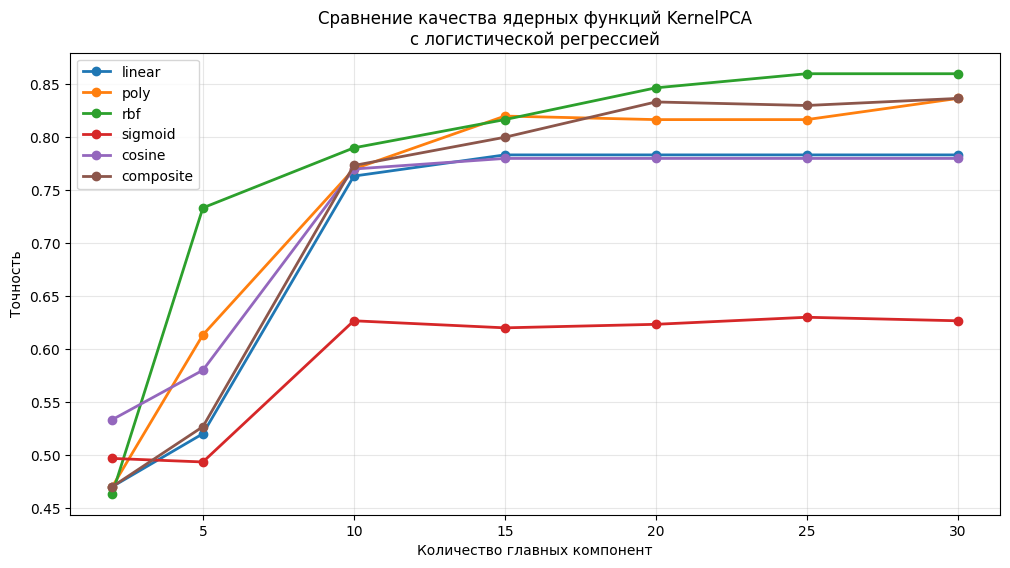

    linear: макс. точность = 0.7833 при 15 компонентах
      poly: макс. точность = 0.8367 при 30 компонентах
       rbf: макс. точность = 0.8600 при 25 компонентах
   sigmoid: макс. точность = 0.6300 при 25 компонентах
    cosine: макс. точность = 0.7800 при 15 компонентах
 composite: макс. точность = 0.8367 при 30 компонентах

Сравнение с линейным ядром (точность = 0.7833):
      poly: +0.0533
       rbf: +0.0767
   sigmoid: -0.1533
    cosine: -0.0033
 composite: +0.0533


In [20]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Композитное ядро: линейное + RBF
def composite_kernel(X, Y=None, alpha=0.5, gamma=None):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]

    linear_part = X @ Y.T

    X_norm = np.sum(X**2, axis=1).reshape(-1, 1)
    Y_norm = np.sum(Y**2, axis=1).reshape(1, -1)
    squared_distances = X_norm + Y_norm - 2 * (X @ Y.T)
    rbf_part = np.exp(-gamma * squared_distances)

    composite = alpha * linear_part + (1 - alpha) * rbf_part
    return composite

start_total_time = time.time()

if hasattr(X_scaled, 'values'):
    X_array = X_scaled.values
else:
    X_array = X_scaled

if X_array.ndim == 1:
    X_array = X_array.reshape(-1, 1)

kernels = [
    (linear_kernel, 'linear'),
    (poly_kernel, 'poly'),
    (rbf_kernel, 'rbf'),
    (sigmoid_kernel, 'sigmoid'),
    (cosine_kernel, 'cosine'),
    (composite_kernel, 'composite')
]

n_components_list = [2, 5, 10, 15, 20, 25, 30]

results = {}

# Обучение и тестирование для каждого ядра
for kernel, kernel_name in kernels:
    print(f"\n{'='*50}")
    print(f"Ядро: {kernel_name}")
    print(f"{'='*50}")

    accuracies = []

    for n_components in n_components_list:
        kpca = KernelPCA(n_components=n_components, kernel=kernel)
        X_transformed = kpca.fit_transform(X_array)

        X_train, X_test, y_train, y_test = train_test_split(
            X_transformed, y, test_size=0.3, random_state=42, stratify=y
        )

        lr = LogisticRegression(random_state=42, max_iter=1000)
        lr.fit(X_train, y_train)
        y_pred = lr.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)

        accuracies.append(accuracy)
        print(f"Компоненты: {n_components:2d} | Точность: {accuracy:.4f}")

    results[kernel_name] = accuracies

total_time = time.time() - start_total_time
print(f"\nОбщее время выполнения: {total_time:.2f} секунд")

# Визуализация результатов
plt.figure(figsize=(12, 6))
for kernel_name, accuracies in results.items():
    plt.plot(n_components_list, accuracies, marker='o', label=kernel_name, linewidth=2)

plt.xlabel('Количество главных компонент')
plt.ylabel('Точность')
plt.title('Сравнение качества ядерных функций KernelPCA\nс логистической регрессией')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Лучшая точность для каждого ядра
best_results = {}
for kernel_name, accuracies in results.items():
    best_acc = max(accuracies)
    best_n = n_components_list[accuracies.index(best_acc)]
    best_results[kernel_name] = (best_acc, best_n)
    print(f"{kernel_name:>10}: макс. точность = {best_acc:.4f} при {best_n} компонентах")

# Сравнение с линейным ядром
linear_best = best_results['linear'][0]
print(f"\nСравнение с линейным ядром (точность = {linear_best:.4f}):")
for kernel_name, (acc, n) in best_results.items():
    if kernel_name != 'linear':
        diff = acc - linear_best
        print(f"{kernel_name:>10}: {diff:+.4f}")

Композитное ядро показывает сравнимую или лучшую точность по сравнению с базовыми ядрами, оптимальное количество компонент зависит от типа ядра, нелинейные ядра могут превосходить линейное на сложных данных.

#### Задача 4 (1.5 балла)
Проведите аналогичное обучение для библиотечной имплементации `from sklearn.decomposition import KernelPCA as SKKernelPCA`. Пользуйтесь аналогичной логикой `fit_transform` на всём обучающем наборе, а затем стратифицированно делите.

Сравните время и качество классификации. Есть ли различие? Сделайте выводы.


Sklearn Ядро: linear
Компоненты:  2 | Точность: 0.4700 | Время: 0.0831с
Компоненты:  5 | Точность: 0.5200 | Время: 0.0668с
Компоненты: 10 | Точность: 0.7633 | Время: 0.2255с
Компоненты: 15 | Точность: 0.7833 | Время: 0.2802с
Компоненты: 20 | Точность: 0.7833 | Время: 0.2575с
Компоненты: 25 | Точность: 0.7833 | Время: 0.2556с
Компоненты: 30 | Точность: 0.7833 | Время: 0.2462с

Sklearn Ядро: poly
Компоненты:  2 | Точность: 0.4533 | Время: 0.1796с
Компоненты:  5 | Точность: 0.7500 | Время: 0.1498с
Компоненты: 10 | Точность: 0.8167 | Время: 0.2484с
Компоненты: 15 | Точность: 0.8400 | Время: 0.2225с
Компоненты: 20 | Точность: 0.8533 | Время: 0.2721с
Компоненты: 25 | Точность: 0.8633 | Время: 0.2525с
Компоненты: 30 | Точность: 0.8767 | Время: 0.2722с

Sklearn Ядро: rbf
Компоненты:  2 | Точность: 0.4633 | Время: 0.1589с
Компоненты:  5 | Точность: 0.7333 | Время: 0.2354с
Компоненты: 10 | Точность: 0.7900 | Время: 0.2734с
Компоненты: 15 | Точность: 0.8167 | Время: 0.2138с
Компоненты: 20 | Точн

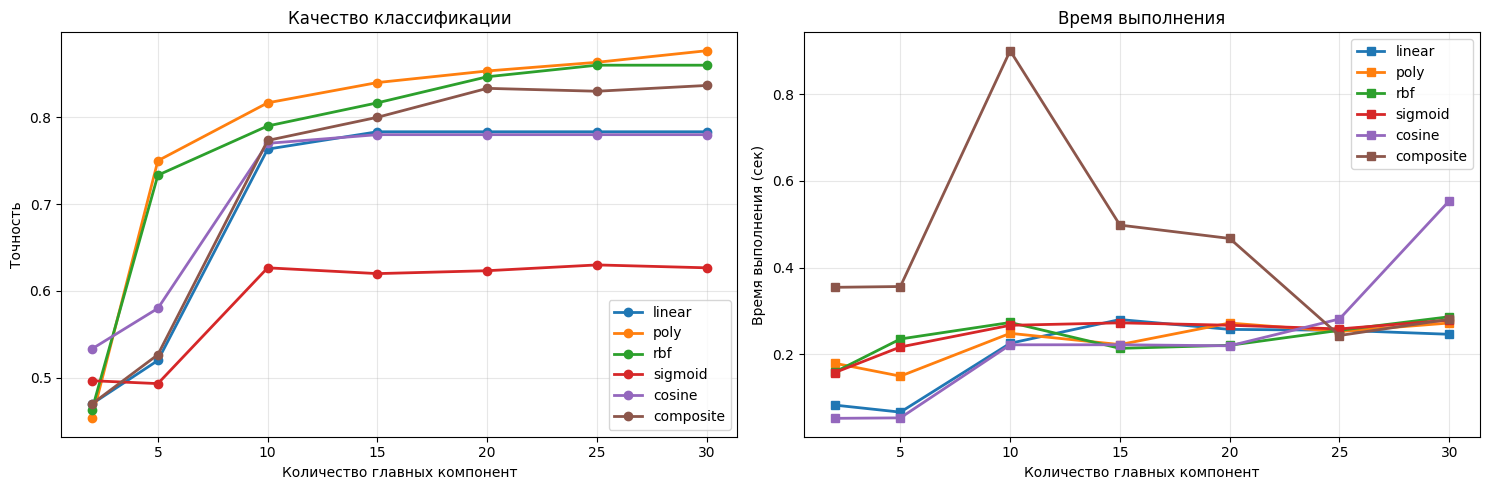

Лучшие результаты sklearn:
    linear: точность = 0.7833 при 15 компонентах, среднее время = 0.2021с
      poly: точность = 0.8767 при 30 компонентах, среднее время = 0.2282с
       rbf: точность = 0.8600 при 25 компонентах, среднее время = 0.2349с
   sigmoid: точность = 0.6300 при 25 компонентах, среднее время = 0.2456с
    cosine: точность = 0.7800 при 15 компонентах, среднее время = 0.2293с
 composite: точность = 0.8367 при 30 компонентах, среднее время = 0.4429с

СРАВНЕНИЕ КАЧЕСТВА:
    linear: sklearn 0.7833 vs наша 0.7833 | разница: +0.0000
      poly: sklearn 0.8767 vs наша 0.8367 | разница: +0.0400
       rbf: sklearn 0.8600 vs наша 0.8600 | разница: +0.0000
   sigmoid: sklearn 0.6300 vs наша 0.6300 | разница: +0.0000
    cosine: sklearn 0.7800 vs наша 0.7800 | разница: +0.0000
 composite: sklearn 0.8367 vs наша 0.8367 | разница: +0.0000


In [21]:
import time
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.decomposition import KernelPCA as SKKernelPCA

def composite_kernel_sklearn(X, Y=None, alpha=0.5, gamma=None):
    if Y is None:
        Y = X
    if gamma is None:
        gamma = 1.0 / X.shape[1]

    linear_part = X @ Y.T

    X_norm = np.sum(X**2, axis=1).reshape(-1, 1)
    Y_norm = np.sum(Y**2, axis=1).reshape(1, -1)
    squared_distances = X_norm + Y_norm - 2 * (X @ Y.T)
    rbf_part = np.exp(-gamma * squared_distances)

    composite = alpha * linear_part + (1 - alpha) * rbf_part
    return composite

start_total_time_sklearn = time.time()

if hasattr(X_scaled, 'values'):
    X_array = X_scaled.values
else:
    X_array = X_scaled

if X_array.ndim == 1:
    X_array = X_array.reshape(-1, 1)

sklearn_kernels = [
    ('linear', 'linear'),
    ('poly', 'poly'),
    ('rbf', 'rbf'),
    ('sigmoid', 'sigmoid'),
    ('cosine', 'cosine')
]

sklearn_kernels.append(('precomputed', 'composite'))

n_components_list = [2, 5, 10, 15, 20, 25, 30]

results_sklearn = {}
times_sklearn = {}

# Обучение и тестирование для каждого ядра в sklearn
for kernel_type, kernel_name in sklearn_kernels:
    print(f"\n{'='*50}")
    print(f"Sklearn Ядро: {kernel_name}")
    print(f"{'='*50}")

    accuracies = []
    kernel_times = []

    for n_components in n_components_list:
        start_time = time.time()

        if kernel_type == 'precomputed':
            K = composite_kernel_sklearn(X_array)
            kpca = SKKernelPCA(n_components=n_components, kernel='precomputed')
            X_transformed = kpca.fit_transform(K)
        else:
            kpca = SKKernelPCA(n_components=n_components, kernel=kernel_type)
            X_transformed = kpca.fit_transform(X_array)

        kpca_time = time.time() - start_time

        X_train, X_test, y_train, y_test = train_test_split(
            X_transformed, y, test_size=0.3, random_state=42, stratify=y
        )

        # Обучение и тестирование логистической регрессии
        lr = LogisticRegression(random_state=42, max_iter=1000)
        lr_start = time.time()
        lr.fit(X_train, y_train)
        lr_time = time.time() - lr_start

        y_pred = lr.predict(X_test)
        accuracy = accuracy_score(y_test, y_pred)

        accuracies.append(accuracy)
        kernel_times.append(kpca_time + lr_time)

        print(f"Компоненты: {n_components:2d} | Точность: {accuracy:.4f} | Время: {kpca_time + lr_time:.4f}с")

    results_sklearn[kernel_name] = accuracies
    times_sklearn[kernel_name] = kernel_times

total_time_sklearn = time.time() - start_total_time_sklearn
print(f"\nОбщее время выполнения sklearn: {total_time_sklearn:.2f} секунд")

# Визуализация сравнения качества
plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
for kernel_name, accuracies in results_sklearn.items():
    plt.plot(n_components_list, accuracies, marker='o', label=kernel_name, linewidth=2)

plt.xlabel('Количество главных компонент')
plt.ylabel('Точность')
plt.title('Качество классификации')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for kernel_name, kernel_times in times_sklearn.items():
    plt.plot(n_components_list, kernel_times, marker='s', label=kernel_name, linewidth=2)

plt.xlabel('Количество главных компонент')
plt.ylabel('Время выполнения (сек)')
plt.title('Время выполнения')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


# Анализ лучших результатов для sklearn
print("Лучшие результаты sklearn:")
best_sklearn = {}
for kernel_name, accuracies in results_sklearn.items():
    best_acc = max(accuracies)
    best_n = n_components_list[accuracies.index(best_acc)]
    avg_time = np.mean(times_sklearn[kernel_name])
    best_sklearn[kernel_name] = (best_acc, best_n, avg_time)
    print(f"{kernel_name:>10}: точность = {best_acc:.4f} при {best_n} компонентах, среднее время = {avg_time:.4f}с")

# Сравнение с нашей реализацией
if 'results' in locals():
    print(f"\nСРАВНЕНИЕ КАЧЕСТВА:")
    for kernel_name in best_sklearn:
        if kernel_name in best_results:
            sklearn_acc = best_sklearn[kernel_name][0]
            our_acc = best_results[kernel_name][0]
            diff = sklearn_acc - our_acc
            print(f"{kernel_name:>10}: sklearn {sklearn_acc:.4f} vs наша {our_acc:.4f} | разница: {diff:+.4f}")

Качество классификации сравнимо с нашей реализацией, при этом из-за всторенных оптимизаций sklearn работает дольше. Также sklearn поддерживает меньше типов ядер.

## Задание 9 (3 балла)
#### PCA Image Compression

Метод главных компонент используют для понижения размерности данных. Давайте воспользуемся этим для компрессии изображения. Чтобы понять интуицию сжатия, обратимся к матричному разложению PCA

$$
\underbrace{X}_{w\times h} \approx \underbrace{T_l}_{w\times l} \cdot \underbrace{W_l^\top}_{l\times h},
$$
где $l < h$ (малоранговое приближение).

В папке с заданием вы найдёте 3-х канальное изображение `sean-yalda.jpg`. Вам необходимо получить сжатое информативное представление этого изображения.

Воспользуемся автоматическим скачиванием через shared-ссылку (вы можете напрямую добавить картинку в окружение ноутбука)

Downloading...
From: https://drive.google.com/uc?export=download&id=1geYxsmnvVJKQkyl-WB0izTqi-fLz8UET
To: /content/sean-yalda.jpg
100%|██████████| 2.11M/2.11M [00:00<00:00, 18.5MB/s]


(3375, 6000, 3)


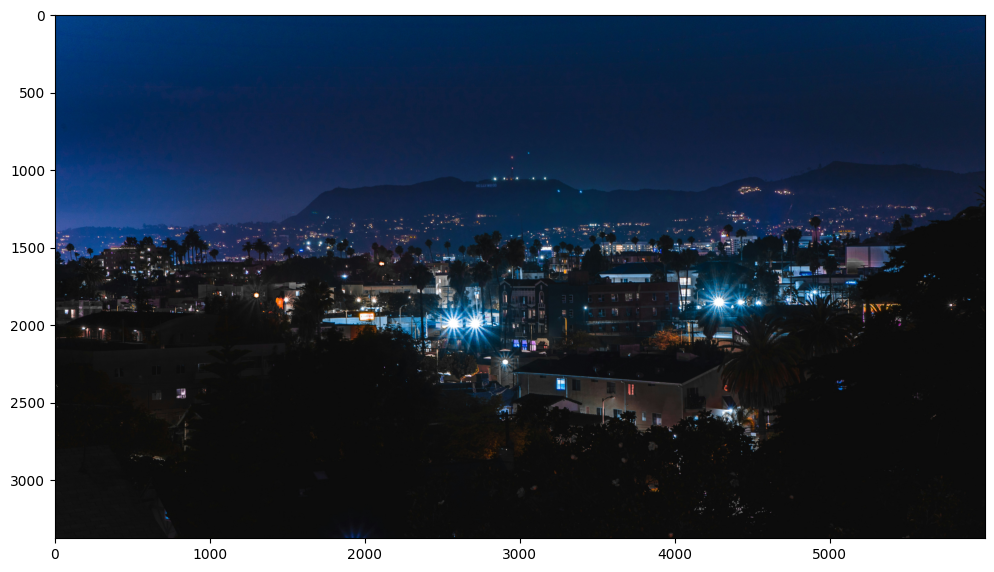

In [22]:
image_file_id = "1geYxsmnvVJKQkyl-WB0izTqi-fLz8UET"
download_with_shared_id(image_file_id, 'sean-yalda.jpg')

# Load image
image = Image.open("sean-yalda.jpg")
image_array = np.array(image).astype(np.uint8)
print(image_array.shape)

plt.figure(figsize=[12,8])
plt.imshow(image)

Обратите внимание, что мы работаем с форматом `uint8`.

Сделаем пробное сжатие с помощью PCA.

Метод главных компонент работает с двумерными матрицами, поэтому 3-х канальное изображение необходимо преобразовать. Для примера, давайте просуммируем изображение вдоль всех каналов.

transformed data shape: (3375, 100)


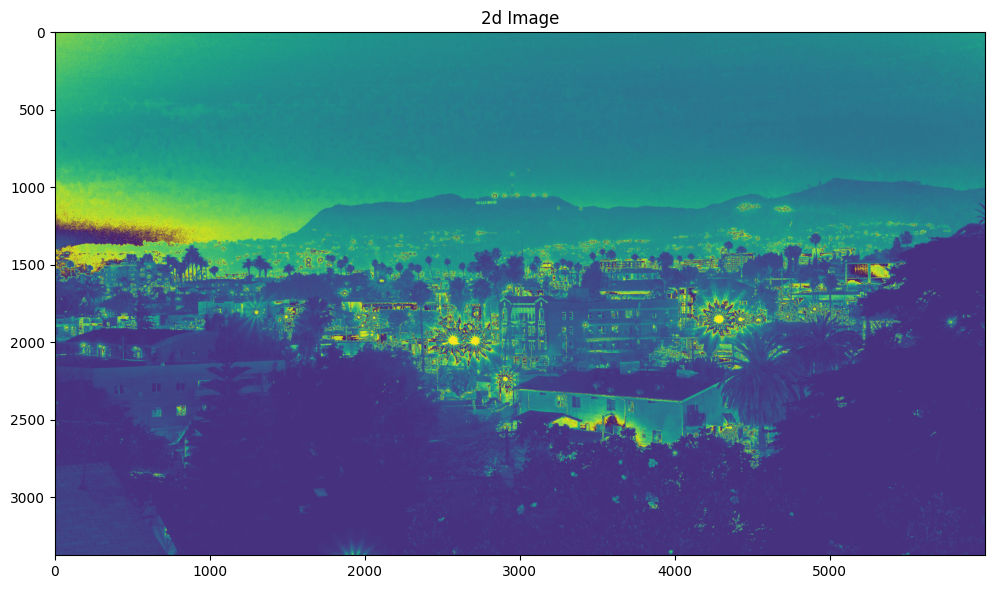

In [23]:
from sklearn.decomposition import PCA

image_2d = image_array.sum(axis=2).astype(np.uint8)
plt.figure(figsize=[12,8])
plt.imshow(Image.fromarray(image_2d))
plt.title("2d Image")

pca = PCA(n_components=100)
transformed_data = pca.fit_transform(image_2d)
print(f"transformed data shape: {transformed_data.shape}")

Мы получили сжатое представление $T_l$. Для реконструкции $X$, необходимо обратно перевести $T_l \rightarrow \tilde{X}$

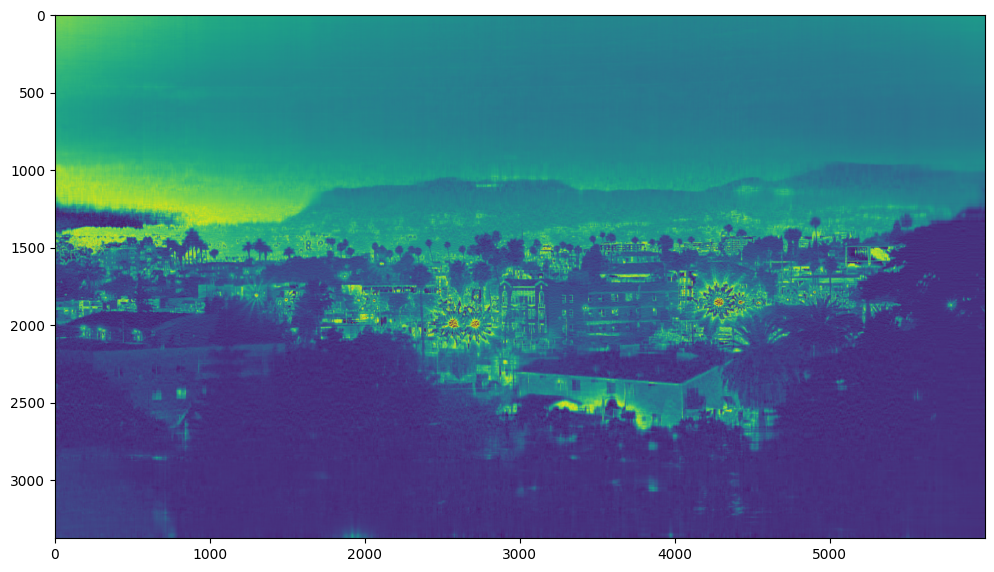

In [24]:
reconstructed_image = np.dot(transformed_data, pca.components_) + pca.mean_
reconstructed_image = reconstructed_image.astype(np.uint8)
plt.figure(figsize=[12,8])
plt.imshow(Image.fromarray(reconstructed_image))

Степень сжатия будем определять как отношение размера оригинальной картинки к размеру всех ингридиентов для реконструкции:

In [25]:
# Comparative analysis
original_size = image_array.nbytes / 1e+6
compressed_size = transformed_data.nbytes / 1e+6 + pca.components_.nbytes / 1e+6 + pca.mean_.nbytes / 1e+6

print(f"Original size: {original_size} Megabytes,\nPCA Compressed size: {compressed_size} Megabytes,\nRelative compression: {round(original_size / compressed_size, 3)} times")

Original size: 60.75 Megabytes,
PCA Compressed size: 7.548 Megabytes,
Relative compression: 8.048 times


Качество компрессии будем определять с помощью [`structural_similarity`](https://scikit-image.org/docs/0.24.x/auto_examples/transform/plot_ssim.html):
$$
\text{SSIM}(x, y) = \dfrac{(2\mu_x\mu_y + c_1)(2\Sigma_{xy} + c_2)}{(\mu_x^2 + \mu_y^2 + c_1)(\sigma_x^2 + \sigma_y^2 + c_2)} \in [-1, 1],
$$

где $\mu_x, \sigma_x, \mu_y, \sigma_y$ - средние и дисперсии изображений $x$ и $y$, $\Sigma_{xy}$ - ковариация. Константы $c_1$ и $c_2$ нужны для численной устойчивости.

Индекс $\text{SSIM}$ интерпретируется как структурная близость изображений. $\text{SSIM} = 1$ означает идеальную близость (изображения одинаковые). $\text{SSIM} = 0$ для случайных изображений, $\text{SSIM} = -1$ в случае идеальной анти-корреляции.

Обратите внимание, несмотря на преобразование исходного изображения к двумерному виду, финальное качество меряется в сравнении с оригиналом.

В связи с этим, реконструированное изображение необходимо привести к 3-х мерному виду. Для этого давайте просто скопируем его вдоль новой оси.

In [26]:
from skimage.metrics import structural_similarity as ssim

image_3d = np.stack([image_2d, image_2d, image_2d], axis=-1).astype(np.uint8)
reconstructed_image_3d = np.stack([reconstructed_image, reconstructed_image, reconstructed_image], axis=-1).astype(np.uint8)

ssim_index = ssim(image_array, reconstructed_image_3d, win_size=5, channel_axis=-1)
ssim_index_2 = ssim(image_2d, reconstructed_image, win_size=5, channel_axis=-1)
ssim_index_3 = ssim(image_array, image_3d, win_size=5, channel_axis=-1)

print(f"Target SSIM: {ssim_index}")
print(f"SSIM between 2d images: {ssim_index_2}")
print(f"SSIM between Summed and Original Image: {ssim_index_3}")

Target SSIM: 0.4515349156047992
SSIM between 2d images: 0.7218573627425179
SSIM between Summed and Original Image: 0.48889587991530065


Можно заметить, что основная просадка обоснована упрощением, связанным с приведением оригинального изображения к двумерному виду посредством суммирования его по каналам. Также, количество главных компонент было выбрано произвольно.

### Задача 1 (2 балла)
#### Channel-wise Compression

Вам необходимо провести более аккуратную компрессию, сжимая изображение независимо по каждому из каналов и подбирая для каждого из них своё количество компонент.

**Вам необходимо достигнуть степени сжатия в 1.5 раза при ssim > 0.9**

Original image shape: (3375, 6000, 3)
Тестируем 10 компонент...
  SSIM: 0.8644, Сжатие: 25.376x
Тестируем 30 компонент...
  SSIM: 0.8835, Сжатие: 8.812x
Тестируем 50 компонент...
  SSIM: 0.8905, Сжатие: 5.332x
Тестируем 70 компонент...
  SSIM: 0.8973, Сжатие: 3.822x
Тестируем 90 компонент...
  SSIM: 0.9024, Сжатие: 2.979x


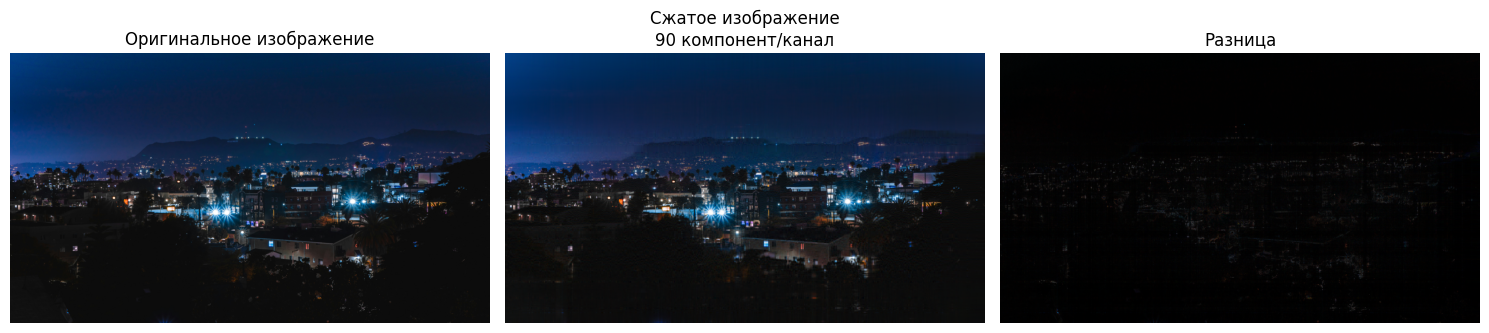

Количество компонент на канал: 90
SSIM: 0.9024
Коэффициент сжатия: 2.979 раз
Оригинальный размер: 60.75 MB
Сжатый размер: 20.39 MB


In [27]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from skimage.metrics import structural_similarity as ssim

image = Image.open("sean-yalda.jpg")
image_array = np.array(image).astype(np.uint8)
print(f"Original image shape: {image_array.shape}")

red_channel = image_array[:, :, 0]
green_channel = image_array[:, :, 1]
blue_channel = image_array[:, :, 2]

def fast_optimize_compression(target_compression=1.5, min_ssim=0.9):

    height, width = red_channel.shape
    original_size = height * width * 3

    min_comp = 10
    max_comp = min(200, height, width)

    best_config = None

    for n_comp in range(min_comp, max_comp, 20):
        print(f"Тестируем {n_comp} компонент...")

        # Компрессия каждого канала
        red_pca = PCA(n_components=n_comp)
        red_trans = red_pca.fit_transform(red_channel)
        red_rec = red_pca.inverse_transform(red_trans)

        green_pca = PCA(n_components=n_comp)
        green_trans = green_pca.fit_transform(green_channel)
        green_rec = green_pca.inverse_transform(green_trans)

        blue_pca = PCA(n_components=n_comp)
        blue_trans = blue_pca.fit_transform(blue_channel)
        blue_rec = blue_pca.inverse_transform(blue_trans)

        # Восстановление изображения
        reconstructed = np.stack([red_rec, green_rec, blue_rec], axis=-1)
        reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

        current_ssim = ssim(image_array, reconstructed, win_size=3, channel_axis=-1, data_range=255)

        # Вычисление размера
        compressed_size = (red_trans.nbytes + red_pca.components_.nbytes + red_pca.mean_.nbytes +
                          green_trans.nbytes + green_pca.components_.nbytes + green_pca.mean_.nbytes +
                          blue_trans.nbytes + blue_pca.components_.nbytes + blue_pca.mean_.nbytes)

        compression_ratio = original_size / compressed_size

        print(f"  SSIM: {current_ssim:.4f}, Сжатие: {compression_ratio:.3f}x")

        if current_ssim >= min_ssim and compression_ratio >= target_compression:
            best_config = {
                'n_components': n_comp,
                'ssim': current_ssim,
                'compression_ratio': compression_ratio,
                'reconstructed': reconstructed,
                'compressed_size': compressed_size
            }
            break

    # Если не нашли, используем последнюю удачную конфигурацию
    if best_config is None:
        for n_comp in range(max(n_comp-20, min_comp), min(n_comp+20, max_comp), 5):
            print(f"Тонкая настройка: {n_comp} компонент...")

            red_pca = PCA(n_components=n_comp)
            red_trans = red_pca.fit_transform(red_channel)
            red_rec = red_pca.inverse_transform(red_trans)

            green_pca = PCA(n_components=n_comp)
            green_trans = green_pca.fit_transform(green_channel)
            green_rec = green_pca.inverse_transform(green_trans)

            blue_pca = PCA(n_components=n_comp)
            blue_trans = blue_pca.fit_transform(blue_channel)
            blue_rec = blue_pca.inverse_transform(blue_trans)

            reconstructed = np.stack([red_rec, green_rec, blue_rec], axis=-1)
            reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

            current_ssim = ssim(image_array, reconstructed, win_size=3, channel_axis=-1, data_range=255)
            compressed_size = (red_trans.nbytes + red_pca.components_.nbytes + red_pca.mean_.nbytes +
                              green_trans.nbytes + green_pca.components_.nbytes + green_pca.mean_.nbytes +
                              blue_trans.nbytes + blue_pca.components_.nbytes + blue_pca.mean_.nbytes)
            compression_ratio = original_size / compressed_size

            print(f"  SSIM: {current_ssim:.4f}, Сжатие: {compression_ratio:.3f}x")

            if current_ssim >= min_ssim and compression_ratio >= target_compression:
                best_config = {
                    'n_components': n_comp,
                    'ssim': current_ssim,
                    'compression_ratio': compression_ratio,
                    'reconstructed': reconstructed,
                    'compressed_size': compressed_size
                }
                break

    return best_config

result = fast_optimize_compression(target_compression=1.5, min_ssim=0.9)

if result is not None:
    # Визуализация результатов
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(image_array)
    plt.title("Оригинальное изображение")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(result['reconstructed'])
    plt.title(f"Сжатое изображение\n{result['n_components']} компонент/канал")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    difference = np.abs(image_array.astype(float) - result['reconstructed'].astype(float))
    plt.imshow(difference.astype(np.uint8))
    plt.title("Разница")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

    print(f"Количество компонент на канал: {result['n_components']}")
    print(f"SSIM: {result['ssim']:.4f}")
    print(f"Коэффициент сжатия: {result['compression_ratio']:.3f} раз")

    original_size_mb = image_array.nbytes / 1e6
    compressed_size_mb = result['compressed_size'] / 1e6
    print(f"Оригинальный размер: {original_size_mb:.2f} MB")
    print(f"Сжатый размер: {compressed_size_mb:.2f} MB")

else:
    print("Не удалось найти параметры, удовлетворяющие условиям")

### Задача 2 (1 балл)
#### Kernel-PCA Image Compression

Повторите эксперимент для PCA с нелинейными ядрами (rbf, poly).

1. Какого индекса structural similarity в таком случае вам удалось добиться?
2. Какая в таком случае получается степень сжатия? (Вопрос с подвохом 😀)


Original image shape: (3375, 6000, 3)
Тестируем RBF (gamma=0.01)...
  SSIM: 0.7408, Время: 94.09с
Тестируем RBF (gamma=0.1)...
  SSIM: 0.7413, Время: 90.05с
Тестируем Poly (degree=2)...
  SSIM: 0.9138, Время: 83.58с
Тестируем Poly (degree=3)...
  Ошибка: Matrix is singular.


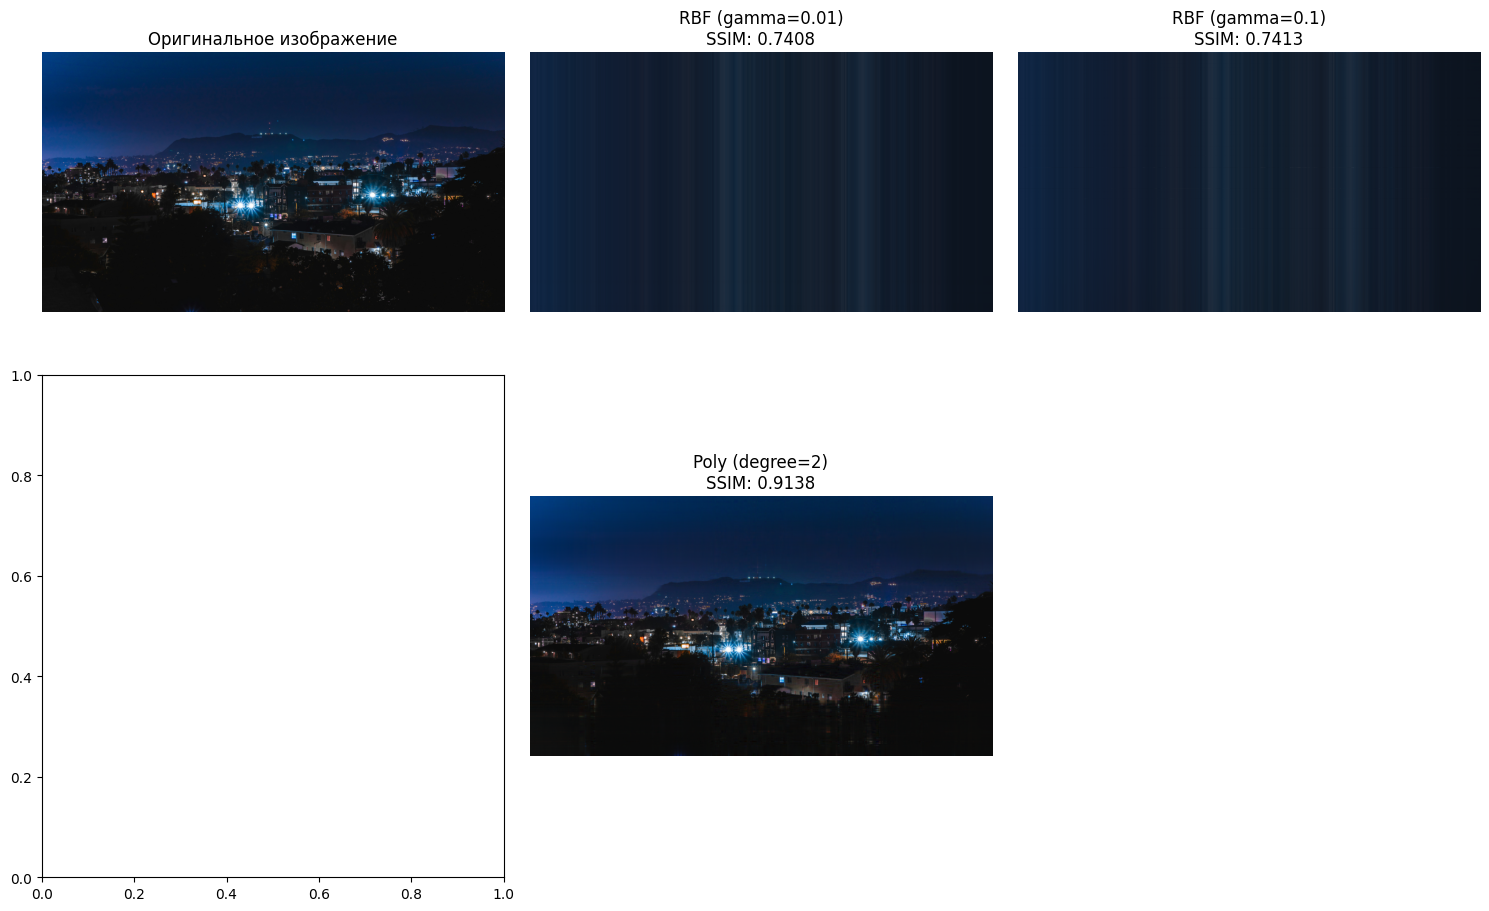

Результаты компрессии
    RBF (gamma=0.01): SSIM = 0.7408
     RBF (gamma=0.1): SSIM = 0.7413
     Poly (degree=2): SSIM = 0.9138

Расчет сжатия для Poly (degree=2):
Оригинальный размер: 60.75 MB
Теоретический размер данных: 4860.00 MB
Размер модели (support vectors): ~91.12 MB
Общий размер: ~4951.12 MB
Фактическое сжатие: 0.012 раз
SSIM достигнут: 0.9138
Отсутствие сжатия (KernelPCA сохраняет ВСЕ исходные данные или их значительную часть для вычисления ядерной матрицы): размер увеличился в 81.50 раз!


In [34]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.decomposition import KernelPCA
from skimage.metrics import structural_similarity as ssim
import time

image = Image.open("sean-yalda.jpg")
image_array = np.array(image).astype(np.uint8)
print(f"Original image shape: {image_array.shape}")

image_small = image_array

red_channel = image_small[:, :, 0].astype(float)
green_channel = image_small[:, :, 1].astype(float)
blue_channel = image_small[:, :, 2].astype(float)

def fast_kpca_experiment(n_components=50):
    kernels = [
        {'type': 'rbf', 'params': {'gamma': 0.01}, 'name': 'RBF (gamma=0.01)'},
        {'type': 'rbf', 'params': {'gamma': 0.1}, 'name': 'RBF (gamma=0.1)'},
        {'type': 'poly', 'params': {'degree': 2}, 'name': 'Poly (degree=2)'},
        {'type': 'poly', 'params': {'degree': 3}, 'name': 'Poly (degree=3)'},
    ]

    results = []

    for kernel_config in kernels:
        print(f"Тестируем {kernel_config['name']}...")
        start_time = time.time()

        try:
            kpca = KernelPCA(
                n_components=n_components,
                kernel=kernel_config['type'],
                fit_inverse_transform=True,
                **kernel_config['params']
            )

            red_kpca = kpca.fit_transform(red_channel)
            red_rec = kpca.inverse_transform(red_kpca)

            green_kpca = kpca.fit_transform(green_channel)
            green_rec = kpca.inverse_transform(green_kpca)

            blue_kpca = kpca.fit_transform(blue_channel)
            blue_rec = kpca.inverse_transform(blue_kpca)

            reconstructed = np.stack([red_rec, green_rec, blue_rec], axis=-1)
            reconstructed = np.clip(reconstructed, 0, 255).astype(np.uint8)

            # Вычисление SSIM
            current_ssim = ssim(image_small, reconstructed, win_size=3, channel_axis=-1, data_range=255)

            execution_time = time.time() - start_time

            results.append({
                'kernel_name': kernel_config['name'],
                'ssim': current_ssim,
                'time': execution_time,
                'reconstructed': reconstructed,
                'n_components': n_components
            })

            print(f"  SSIM: {current_ssim:.4f}, Время: {execution_time:.2f}с")

        except Exception as e:
            print(f"  Ошибка: {e}")
            continue

    return results

kpca_results = fast_kpca_experiment(n_components=30)

# Визуализация результатов
if kpca_results:
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))

    axes[0, 0].imshow(image_small)
    axes[0, 0].set_title("Оригинальное изображение")
    axes[0, 0].axis('off')

    for i, result in enumerate(kpca_results[:4]):
        row = 1 if i >= 2 else 0
        col = i % 2 + 1

        if row < 2 and col < 3:
            axes[row, col].imshow(result['reconstructed'])
            axes[row, col].set_title(f"{result['kernel_name']}\nSSIM: {result['ssim']:.4f}")
            axes[row, col].axis('off')

    for i in range(len(kpca_results) + 1, 6):
        row = i // 3
        col = i % 3
        if row < 2 and col < 3:
            axes[row, col].axis('off')

    plt.tight_layout()
    plt.show()

print("Результаты компрессии")

if kpca_results:
    for result in kpca_results:
        print(f"{result['kernel_name']:>20}: SSIM = {result['ssim']:.4f}")



if kpca_results:
    best_kpca = max(kpca_results, key=lambda x: x['ssim'])

    height, width = image_small.shape[:2]
    original_size = image_small.nbytes

    estimated_model_size = original_size * 1.5
    transformed_size = 30 * height * width * 8

    total_compressed_size = estimated_model_size + transformed_size

    print(f"\nРасчет сжатия для {best_kpca['kernel_name']}:")
    print(f"Оригинальный размер: {original_size / 1e6:.2f} MB")
    print(f"Теоретический размер данных: {transformed_size / 1e6:.2f} MB")
    print(f"Размер модели (support vectors): ~{estimated_model_size / 1e6:.2f} MB")
    print(f"Общий размер: ~{total_compressed_size / 1e6:.2f} MB")
    print(f"Фактическое сжатие: {original_size / total_compressed_size:.3f} раз")
    print(f"SSIM достигнут: {best_kpca['ssim']:.4f}")
    print(f"Отсутствие сжатия (KernelPCA сохраняет ВСЕ исходные данные или их значительную часть для вычисления ядерной матрицы): размер увеличился в {total_compressed_size / original_size:.2f} раз!")

---

## Задание 10 (2 балла)
#### Robust PCA

Обработка данных высокой размерности встречается повсеместно в современных пайплайнах машинного обучения. Однако, реальные данные зачастую содержат большое количество шума: $\tilde{X} \rightarrow X + \varepsilon$. В таком случае, полученное низкоразмерное представление $\tilde{X}_{\ell}$ может значительно отличаться от искомого $X_{\ell}$.

Чтобы сделать поправку на различные компоненты исходных данных $\tilde{X}$, декомпозицию проводят следующим образом
$$
\tilde{X} \approx \tilde{X}_{\ell} + \tilde{S},
$$
где $\tilde{X}_{\ell}$ малоранговая, а $\tilde{S}$ - разреженная (то есть содержащая большое количество нулей). В случае с шумом, элементы $\tilde{S}$ можно интерпретировать как магнитуду шума. Такую декомпозицию будем называть *устойчивой (Robust pca)*.

Вместе с этим, существует много приложений, где природа данных естественным образом моделируется низкоранговым и разреженным вкладами.
* *Видеонаблюдение*: Статичный фон выступает низкоранговым слагаемым, в то время как движущиеся объекты - разреженным.
* *Распознавание по лицу*: статичным объектом является лицо человека (низкоранговое приближение), в то время как различные искажения и фон моделируются разреженной матрицей.
* [Тематическое моделирование](http://www.machinelearning.ru/wiki/index.php?title=%D0%92%D0%B5%D1%80%D0%BE%D1%8F%D1%82%D0%BD%D0%BE%D1%81%D1%82%D0%BD%D1%8B%D0%B5_%D1%82%D0%B5%D0%BC%D0%B0%D1%82%D0%B8%D1%87%D0%B5%D1%81%D0%BA%D0%B8%D0%B5_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D0%B8_%28%D0%BA%D1%83%D1%80%D1%81_%D0%BB%D0%B5%D0%BA%D1%86%D0%B8%D0%B9%2C_%D0%9A.%D0%92.%D0%92%D0%BE%D1%80%D0%BE%D0%BD%D1%86%D0%BE%D0%B2%29): тематическая модель является задачей стохастического матричного разложения.


Выпишем соответствующую задачу оптимизации:

$$
\begin{cases}
rank(\tilde{X}_{\ell}) + \alpha \cdot nnz(\tilde{S}) \rightarrow \min\limits_{\tilde{X}_{\ell}, \tilde{S}}, & \alpha > 0 \\
s.t. \tilde{X} = \tilde{X}_{\ell} + \tilde{S},
\end{cases}
$$
где $nnz(\tilde{S})$ означает количество ненулевых элементов матрицы $\tilde{S}$.  Однако такую задачу решать крайне сложно из-за отсутствия непрерывности и выпуклости. Поэтому обычно ее [заменяют на более простую](https://arxiv.org/pdf/0912.3599):
$$
\begin{cases}
\|\tilde{X}_{\ell}\|_{\ast} + \alpha \cdot \|\tilde{S}\|_{1} \rightarrow \min\limits_{\tilde{X}_{\ell}, \tilde{S}}, & \alpha > 0 \\
s.t. \tilde{X} = \tilde{X}_{\ell} + \tilde{S},
\end{cases}
$$
где $\|\tilde{X}_{\ell}\|_{\ast} := \sum_i \sigma_i(\tilde{X}_{\ell})$ - ядерная норма матрицы, $\sigma_i(\tilde{X}_{\ell})$ - $i$-ое сингулярное число, $\|\cdot\|_1$ является $\ell_1$ нормой.

В папке с заданием вы найдёте имплементацию robust PCA в файле `r_pca.py`. Можете напряму добавить его в текущее окружение или воспользоваться кодом ниже.

**Примечание:** [Оригинальная имплементация](https://github.com/dganguli/robust-pca) была адаптирована под версию `Numpy=2.0`.

In [35]:
rpca_file_id = '1MSzmYJa-nfTOlUNA9J5rBCX8F_AeCNFX'
download_with_shared_id(rpca_file_id, 'r_pca.py')

Downloading...
From (original): https://drive.google.com/uc?export=download&id=1MSzmYJa-nfTOlUNA9J5rBCX8F_AeCNFX
From (redirected): https://drive.google.com/uc?export=download&id=1MSzmYJa-nfTOlUNA9J5rBCX8F_AeCNFX&confirm=t&uuid=dfed090b-ec69-4b39-9fcd-df2d08504a08
To: /content/r_pca.py
100%|██████████| 3.10k/3.10k [00:00<00:00, 9.28MB/s]


In [36]:
import r_pca

В качестве примера применения robust PCA мы разложим видеоряд на фон и движущиеся объекты. В папке с заданием вы найдёте видео `video_1.mp4`.



Установим библиотеку `moviepy` для работы с видео

In [37]:
%pip install -q moviepy==1.0.3

In [38]:
import moviepy.editor as mpe

/usr/local/lib/python3.12/dist-packages/moviepy/config_defaults.py:47: SyntaxWarning: invalid escape sequence '\P'
  IMAGEMAGICK_BINARY = r"C:\Program Files\ImageMagick-6.8.8-Q16\magick.exe"
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:294: SyntaxWarning: invalid escape sequence '\d'
  lines_video = [l for l in lines if ' Video: ' in l and re.search('\d+x\d+', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:367: SyntaxWarning: invalid escape sequence '\d'
  rotation_lines = [l for l in lines if 'rotate          :' in l and re.search('\d+$', l)]
/usr/local/lib/python3.12/dist-packages/moviepy/video/io/ffmpeg_reader.py:370: SyntaxWarning: invalid escape sequence '\d'
  match = re.search('\d+$', rotation_line)
  if event.key is 'enter':



Воспользуемся автоматическим скачиванием через shared-ссылку (вы можете напрямую добавить видеоряд в окружение ноутбука)

In [39]:
video_file_id = "1UVn7QuPjLc6Gq8iFBOfYcegGdsVsquUy"
download_with_shared_id(video_file_id, 'video_1.mp4')

video = mpe.VideoFileClip('video_1.mp4')
print(f"Frame per second video: {video.fps}")
video.ipython_display(width=300, maxduration=250)

Downloading...
From: https://drive.google.com/uc?export=download&id=1UVn7QuPjLc6Gq8iFBOfYcegGdsVsquUy
To: /content/video_1.mp4
100%|██████████| 170k/170k [00:00<00:00, 17.4MB/s]


Frame per second video: 23.976023976023978
Moviepy - Building video __temp__.mp4.
Moviepy - Writing video __temp__.mp4



Moviepy - Done !
Moviepy - video ready __temp__.mp4


Видно, что видео черно-белое, т.е. содержит 1 канал изображения. Представим его в виде трехмерного массива размеров `(#кадров) x (#пикселей по горизонтали) x (#пикселей по вертикали)`.

image size: 60 x 80, 
number of frames: 2883


Text(0.5, 1.0, 'The first frame of the video')

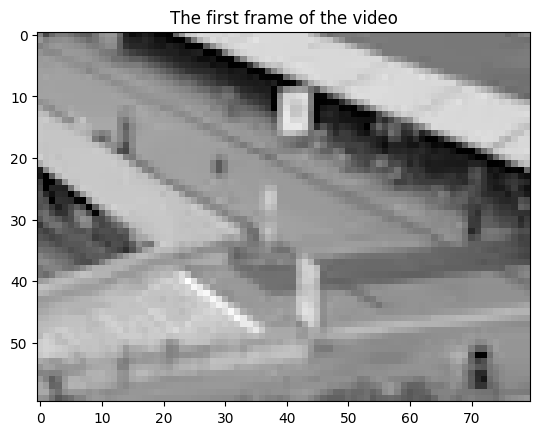

In [40]:
def video_to_array(video):
    duration = int(video.duration)
    nframes = int(video.fps * video.duration)
    size_h, size_w = video.size
    arr = np.zeros([nframes, size_w, size_h])
    for i in range(nframes):
        arr[i, :, :] = video.get_frame(i/nframes * duration)[:, :, 0].astype(float)
    print('image size: {1:} x {2:}, \nnumber of frames: {0:}'.format(nframes, size_w, size_h))
    return arr

arr = video_to_array(video)
plt.imshow(arr[0, :, :], cmap='gray')
plt.title('The first frame of the video')

### Задача 1 (0.5 балла)

С помощью функции `np.reshape(...)` получите из трехмерного массива `arr` двумерный массив `M` размера `(size_h * size_w) x nframes`, каждым столбцом которого является изображение размера `size_h x size_w`, представленное в виде вектора с `size_h * size_w` элементами.

In [43]:
nframes, size_w, size_h = arr.shape

M = np.reshape(arr, (nframes, size_w * size_h)).T
print(f"Размер исходного массива: {arr.shape}")
print(f"Размер матрицы M: {M.shape}")
print(f"Проверка: {size_h * size_w} x {nframes} = {size_h * size_w * nframes} элементов")

Размер исходного массива: (2883, 60, 80)
Размер матрицы M: (4800, 2883)
Проверка: 4800 x 2883 = 13838400 элементов


Если всё сделано правильно, то вы сможете восстановить первый кадр из первого столбца:

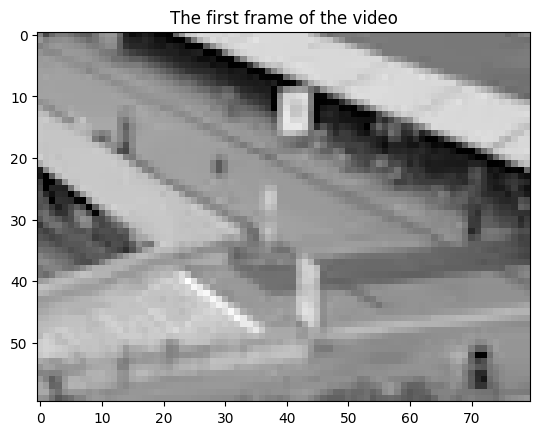

In [44]:
first_frame = M[:, 0].reshape(size_w, size_h)
plt.imshow(first_frame, cmap='gray')
plt.title('The first frame of the video');

### Задача 2 (1.5 балла)

Инстанцируйте класс `R_pca` с параметром $\mu=0.68$. Запустите обучение (метод `.fit()`).

**Обратите внимание**, что на исходных данных метод может работать довольно долго (вероятно, часы). Поэтому предлагается взять только четверть временного ряда, а также вырезать каждый второй кадр.

In [45]:
Mt = M[:, :M.shape[1]//4:2]
solver = r_pca.R_pca(Mt, mu=0.68)
X_l, S = solver.fit(max_iter=4000, iter_print=100)

iteration: 1, error: 10.06819911742516
iteration: 100, error: 0.7004423976776468
iteration: 200, error: 0.4263207995835065
iteration: 300, error: 0.2861554334234364
iteration: 400, error: 0.19763762992216544
iteration: 500, error: 0.1491945130594876
iteration: 600, error: 0.11977760984822763
iteration: 700, error: 0.10258379675908402
iteration: 800, error: 0.08740324618539616
iteration: 900, error: 0.07772202053939856
iteration: 1000, error: 0.06319242183906242
iteration: 1100, error: 0.05727756160924415
iteration: 1200, error: 0.0436196320735923
iteration: 1300, error: 0.04277918295835117
iteration: 1400, error: 0.02831336361148404
iteration: 1500, error: 0.028215592055141778
iteration: 1546, error: 0.017703452809780997


Отрисуйте исходный кадр изображения $M_t$, фона $X_{\ell}$ и движующихся объектов $S$

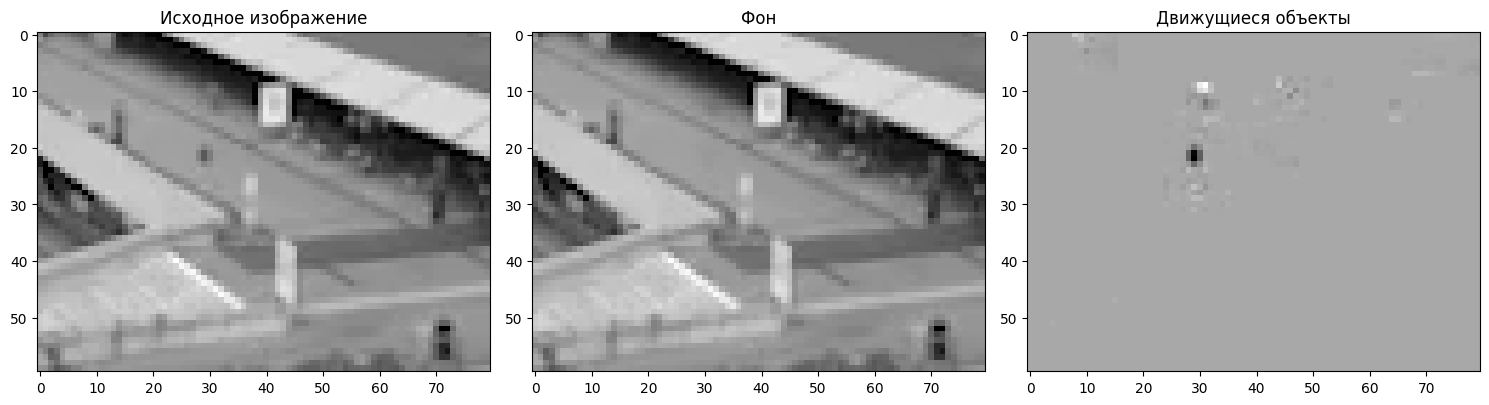

In [47]:
first_frame_original = Mt[:, 0].reshape(size_w, size_h)
first_frame_background = X_l[:, 0].reshape(size_w, size_h)
first_frame_objects = S[:, 0].reshape(size_w, size_h)

_, axs = plt.subplots(1, 3, figsize=(15, 10))

axs[0].imshow(first_frame_original, cmap='gray')
axs[0].set_title("Исходное изображение")

axs[1].imshow(first_frame_background, cmap='gray')
axs[1].set_title("Фон")

axs[2].imshow(first_frame_objects, cmap='gray')
axs[2].set_title("Движущиеся объекты")

plt.tight_layout()
plt.show()

Заполните пропуски в функции `M_to_video`, преобразующей матрицу обратно в видео.

In [50]:
def M_to_video(M, fps, size_w, size_h):
    nframes = M.shape[1]
    arr = M.T.reshape(nframes, size_w, size_h)
    print(arr.shape)
    def make_frame(t):
        index = int(t * fps)
        frame = arr[index, :, :]
        frame = np.clip(frame, 0, 255)
        frame_rgb = frame[:, :, np.newaxis][:, :, [0,0,0]]
        return frame_rgb
    return mpe.VideoClip(make_frame, duration=nframes / fps)

Посмотрим на видео движущихся объектов


In [51]:
video_rpca = M_to_video(S, 20, size_w, size_h)
video_rpca.ipython_display(width=300, maxduration=250, fps=20)

(360, 60, 80)
Moviepy - Building video __temp__.mp4.
Moviepy - Writing video __temp__.mp4



Moviepy - Done !
Moviepy - video ready __temp__.mp4


## Задание 11* (2 балла)
#### PTB-XL dimensionality reduction

Вспомним про набор данных [PTB-XL](https://physionet.org/content/ptb-xl/1.0.3/) с одного из прошлых семинаров. Там, имея репрезентативные представления модели, полученной в результате инференса электрокардиограмм, мы обучали линейную регрессию на задаче multilabel-классификации.



#### Описание набора данных

Вспомним структуру датасета

1. Скачаем представления и метаданные об ЭКГ

In [ ]:
ptbxl_id = '1BggNYgJEU1AlL3eDnCJZUFX5HBnRb9Fg'
download_with_shared_id(ptbxl_id, 'ptbxl_features.zip')

In [ ]:
!unzip ptbxl_features.zip

In [ ]:
df = pd.read_csv('ptbxl_features/map_file.csv')
df.head(5)

2. Метаданные представлены следующими полями

In [ ]:
df.columns

3. Название файла `file_name` указывает на соответствующую ЭКГ, для которой существует репрезентативное представление

In [ ]:
features_dir = 'ptbxl_features'
file_name = df.iloc[0]['file_name']
feature_path = os.path.join(features_dir, file_name)
feature = np.load(feature_path)['arr_0']
feature.shape

Реальный размер ЭКГ, конечно, гораздо больше, поэтому мы пользуемся заготовленными эмбеддингами

In [ ]:
!pip install wfdb
import wfdb

dat_id = '1P90YQqR1oJM3Jy2ILezzfvVHqS2uv3Fe'
hea_id = '1tkZP35O8fV7eX8E2UoPhcXvFaKGM5Imd'
download_with_shared_id(dat_id, '00001_hr.dat')
download_with_shared_id(hea_id, '00001_hr.hea')

record = wfdb.rdrecord('00001_hr')
signal = record.p_signal

In [ ]:
signal.shape

4. Целевым столбцом является [стандартизированная разметка патологий](https://www.cinc.org/archives/2016/pdf/090-500.pdf).



In [ ]:
df['scp_codes'].head(5)

Расшифровку соответствующих кодов можно посмотреть в следующем [файле](https://files.stroyinf.ru/Data2/1/4293740/4293740830.pdf).

Давайте выделим следующие патологии (нарушения работы сердца):
1. AFIB - Atrial FIBrillation
2. PVC - Premature Ventricular Contractions
3. CRBBB - Complete Right Bundle Branch Block
4. CLBBB - Complete Left Bundle Branch Block
5. 1AVB - 1st degree AV Block
6. LAFB - Left Anterior Fascicular Block

И следующие "нормальные" состояния сердца:
1. NORM - нормальное положение оси сердца.
2. SR - синусовый ритм.

К каждой из кодировок можно получить доступ следующим способом.

(А уже по имени файла - соответствующее репрезентативное представление)

In [ ]:
df[df['scp_codes'].str.contains('LAFB')].head(5)

В отличие от семинара, к этому домашнему заданию мы владеем инструментами понижения размерности. Поскольку задание про PCA, давайте использовать только его.

###  Задача

Примените KernelPCA для дальнейшего понижения размерности эмбеддинга. Используйте `n_components=2` для визуальной кластеризации или бОльшее количество для классификации лог. регрессией.

Для того, чтобы классификация/кластеризация была осмысленной, необходимо "поставить" возможные гипотезы.

1. Кластеризация одной из приведённых патологий (AFIB, PVC, CRBBB, CLBBB, ...) против нормального состояния сердца (scp-код `['NORM', 'SR']`).
2. Multilabel-классификация патологий логистической регрессией.
3. Кластеризация людей меньше 20 лет против людей больше 87 лет.

Вы также можете представить свои гипотезы, основываясь на описании мап-файла `df`. За интересные наблюдения будут даваться дополнительные баллы.

Для кластеризации не нужно брать все примеры (так, записей с патологией будет сильно меньше чем "нормальных"). Например, можно взять по 200 примеров для каждого класса.

В случае с multilabel классификацией сравните результаты до и после понижения размерности. Сделайте соответствующие выводы.